In [ ]:
! pip install biopython

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 35.2 MB/s eta 0:00:00


## OBTENEMOS LOS CRISTALES EXPERIMENTALES ##

In [ ]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

import os
from Bio.PDB import PDBList, PDBParser, PDBIO, Select, is_aa

PDB_IDS = ["1AKE", "4AKE"]
OUT_DIR = "pdb_chainA_protein_only"
CHAIN_ID = "A"

class ChainAProteinOnly(Select):
    def __init__(self, chain_id="A"):
        self.chain_id = chain_id

    def accept_chain(self, chain):
        return 1 if chain.id == self.chain_id else 0

    def accept_residue(self, residue):
        # Keep only standard amino acids (protein). This excludes waters/ligands/ions.
        return 1 if is_aa(residue, standard=True) else 0

    def accept_atom(self, atom):
        # Keep all atoms of kept residues (including hydrogens if present)
        return 1

def download_and_clean(pdb_id: str, out_dir: str, chain_id: str = "A"):
    os.makedirs(out_dir, exist_ok=True)

    pdbl = PDBList()
    downloaded_path = pdbl.retrieve_pdb_file(pdb_id, pdir=out_dir, file_format="pdb")

    parser = PDBParser(QUIET=True)
    structure = parser.get_structure(pdb_id, downloaded_path)

    # Optional: sanity check chain exists in first model
    model = structure[0]
    chains = {c.id for c in model.get_chains()}
    if chain_id not in chains:
        raise ValueError(f"{pdb_id}: chain '{chain_id}' not found. Available: {sorted(chains)}")

    out_path = os.path.join(out_dir, f"{pdb_id}_chain{chain_id}_protein_only.pdb")
    io = PDBIO()
    io.set_structure(structure)
    io.save(out_path, select=ChainAProteinOnly(chain_id))

    return downloaded_path, out_path

def main():
    for pdb_id in PDB_IDS:
        dl, outp = download_and_clean(pdb_id, OUT_DIR, CHAIN_ID)
        print(f"{pdb_id}: downloaded -> {dl}")
        print(f"{pdb_id}: cleaned (chain {CHAIN_ID}, protein only) -> {outp}")

if __name__ == "__main__":
    main()


1AKE: downloaded -> pdb_chainA_protein_only/pdb1ake.ent
1AKE: cleaned (chain A, protein only) -> pdb_chainA_protein_only/1AKE_chainA_protein_only.pdb
4AKE: downloaded -> pdb_chainA_protein_only/pdb4ake.ent
4AKE: cleaned (chain A, protein only) -> pdb_chainA_protein_only/4AKE_chainA_protein_only.pdb


## CALCULAMOS LOS CONTACTOS DE CADA CRISTAL EXPERIMENTAL ##

In [ ]:
# pip install biopython numpy pandas scipy
from Bio.PDB import PDBParser, is_aa
import numpy as np
import pandas as pd
from scipy.spatial import cKDTree as KDTree

# =========================
# CONFIG
# =========================
PDB_PATH = "/content/pdb_chainA_protein_only/1AKE_chainA_protein_only.pdb"   # cambia esto

CUTOFF = 5.2          # C (Å): vecindad átomo–átomo
SHADOW_S = 1.3        # S (Å): radio de oclusión alrededor del segmento
MIN_SEQ_SEP = 3       # excluye 1–2 y 1–3 (|Δseq| <= 2) en la misma cadena

TARGET_CHAIN = "A"    # para la matriz (puede ser None si no querés matriz)
CHAIN_ID = None       # None = usar todas las cadenas; "A" = restringir análisis a una cadena
ALLOW_INTERCHAINS = False  # True = permite contactos entre cadenas (útil para cristal)
EXCLUDE_WATER = True       # True = excluye HOH/WAT
STANDARD_AA_ONLY = True    # True = solo aa estándar

OUT_CONTACTS = "1AKE_residue_contacts_shadow.csv"
OUT_MATRIX = "contact_matrix_1AKE_chainA_shadow.csv"

# =========================
# HELPERS
# =========================
def chain_ok(cid: str) -> bool:
    return True if CHAIN_ID is None else (cid == CHAIN_ID)

def is_heavy(atom) -> bool:
    """Excluye H/D/T si aparecieran; fallback por nombre si atom.element no está."""
    el = (atom.element or "").upper()
    if not el:
        name = atom.get_name().strip()
        el = "".join([c for c in name if c.isalpha()])[:1].upper()
    return el not in {"H", "D", "T"}

def point_segment_distance(p, a, b):
    """Distancia de p al segmento ab y parámetro t de proyección."""
    ab = b - a
    ap = p - a
    ab2 = float(np.dot(ab, ab))
    if ab2 == 0.0:
        return float(np.linalg.norm(ap)), 0.0
    t = float(np.dot(ap, ab) / ab2)
    t = max(0.0, min(1.0, t))
    proj = a + t * ab
    return float(np.linalg.norm(p - proj)), t

def resid_key(chain_id, res):
    """Clave estable de residuo: (chain, resseq, icode)."""
    return (chain_id, int(res.id[1]), str(res.id[2] or " "))

def normalize_pair(a, b):
    """Orden estable para pares de residuos."""
    return tuple(sorted([a, b]))

def harvest_heavy_atoms(model):
    """
    Devuelve:
      atoms: lista de dicts con coords y metadata
      res_order: dict (chain, resseq, icode)-> índice secuencial por cadena (para MIN_SEQ_SEP)
      res_info: dict (chain, resseq, icode)-> resname
    """
    res_order = {}
    res_info = {}

    # Orden secuencial por cadena
    for ch in model:
        if not chain_ok(ch.id):
            continue
        residues = []
        for r in ch:
            if EXCLUDE_WATER and r.id[0] in {"W"}:
                continue
            if STANDARD_AA_ONLY:
                if not is_aa(r, standard=True):
                    continue
            else:
                if not is_aa(r):
                    continue
            residues.append(r)

        residues.sort(key=lambda r: (r.id[1], r.id[2] or " "))
        for i, r in enumerate(residues):
            k = resid_key(ch.id, r)
            res_order[k] = i
            res_info[k] = r.get_resname()

    # Átomos
    atoms = []
    idx = 0
    for ch in model:
        if not chain_ok(ch.id):
            continue
        for r in ch:
            if EXCLUDE_WATER and r.id[0] in {"W"}:
                continue
            if STANDARD_AA_ONLY:
                if not is_aa(r, standard=True):
                    continue
            else:
                if not is_aa(r):
                    continue

            rk = resid_key(ch.id, r)
            seq_index = res_order.get(rk, None)

            for a in r:
                if not is_heavy(a):
                    continue
                atoms.append(
                    dict(
                        idx=idx,
                        chain=ch.id,
                        reskey=rk,
                        resname=r.get_resname(),
                        atom=a.get_name().strip(),
                        coord=a.get_coord().astype(float),
                        seq_index=seq_index,
                    )
                )
                idx += 1

    return atoms, res_order, res_info

# =========================
# SHADOW CONTACTS (single structure)
# =========================
def shadow_contacts_residue_single(model):
    atoms, _, res_info = harvest_heavy_atoms(model)
    if not atoms:
        return {}, res_info

    coords = np.vstack([a["coord"] for a in atoms])
    tree = KDTree(coords)

    # Par residuo-residuo -> distancia mínima (entre átomos pesados NO-sombreados)
    pair_min_d = {}

    for i, ai in enumerate(atoms):
        neigh = tree.query_ball_point(ai["coord"], CUTOFF)
        for j in neigh:
            if j <= i:
                continue
            aj = atoms[j]

            # Filtro inter-cadenas
            if (not ALLOW_INTERCHAINS) and (ai["chain"] != aj["chain"]):
                continue

            # Excluir 1–2 y 1–3 (misma cadena)
            if ai["chain"] == aj["chain"] and ai["seq_index"] is not None and aj["seq_index"] is not None:
                if abs(ai["seq_index"] - aj["seq_index"]) <= (MIN_SEQ_SEP - 1):
                    continue

            A = ai["coord"]
            B = aj["coord"]
            d = float(np.linalg.norm(A - B))
            if d > CUTOFF or d <= 1e-6:
                continue

            # Candidatos para oclusión alrededor del punto medio
            midpoint = 0.5 * (A + B)
            search_r = 0.5 * d + SHADOW_S
            cand = tree.query_ball_point(midpoint, search_r)

            # Ajuste conservador como tu pipeline (si Δseq == MIN_SEQ_SEP)
            S_eff = SHADOW_S
            if ai["chain"] == aj["chain"] and ai["seq_index"] is not None and aj["seq_index"] is not None:
                if abs(ai["seq_index"] - aj["seq_index"]) == MIN_SEQ_SEP:
                    S_eff = min(SHADOW_S, 0.5)

            shadowed = False
            for k in cand:
                if k == i or k == j:
                    continue
                P = coords[int(k)]
                # prune rápido: si está lejos de ambos extremos
                if np.linalg.norm(P - A) >= d and np.linalg.norm(P - B) >= d:
                    continue
                dist, t = point_segment_distance(P, A, B)
                if dist <= S_eff and 0.0 <= t <= 1.0:
                    shadowed = True
                    break
            if shadowed:
                continue

            # Registrar contacto a nivel residuo-residuo
            rpi = ai["reskey"]
            rpj = aj["reskey"]
            pair = normalize_pair(rpi, rpj)

            prev = pair_min_d.get(pair, None)
            if prev is None or d < prev:
                pair_min_d[pair] = d

    return pair_min_d, res_info

def build_contact_df(pair_min_d, res_info):
    rows = []
    for (ci, ri, ii), (cj, rj, ij), in pair_min_d.keys():
        d = pair_min_d[((ci, ri, ii), (cj, rj, ij))]
        rows.append(
            dict(
                chain1=ci,
                resn1=res_info.get((ci, ri, ii), ""),
                resi1=int(ri),
                icode1=str(ii),
                chain2=cj,
                resn2=res_info.get((cj, rj, ij), ""),
                resi2=int(rj),
                icode2=str(ij),
                dist_A=float(d),  # “distancia mínima” entre átomos pesados NO-sombreados
            )
        )
    df = pd.DataFrame(rows).sort_values(["chain1", "resi1", "icode1", "chain2", "resi2", "icode2"])
    return df

def build_chain_matrix(df_contacts, chain_id, res_info):
    # residuos de esa cadena (únicos) ordenados por (resseq, icode)
    keys = sorted(
        [k for k in res_info.keys() if k[0] == chain_id],
        key=lambda x: (x[1], x[2])
    )
    key_to_idx = {k: i for i, k in enumerate(keys)}
    n = len(keys)
    M = np.zeros((n, n), dtype=int)

    # Solo contactos intra-cadena en esa cadena
    for _, r in df_contacts.iterrows():
        if r["chain1"] == chain_id and r["chain2"] == chain_id:
            k1 = (chain_id, int(r["resi1"]), str(r["icode1"]))
            k2 = (chain_id, int(r["resi2"]), str(r["icode2"]))
            if k1 in key_to_idx and k2 in key_to_idx:
                i = key_to_idx[k1]
                j = key_to_idx[k2]
                M[i, j] = 1
                M[j, i] = 1

    # opcional: devolver también etiquetas
    labels = [f"{k[1]}{'' if k[2].strip()=='' else k[2].strip()}" for k in keys]
    return M, labels

# =========================
# RUN
# =========================
parser = PDBParser(QUIET=True)
structure = parser.get_structure("prot", PDB_PATH)
model = structure[0]

pair_min_d, res_info = shadow_contacts_residue_single(model)
df = build_contact_df(pair_min_d, res_info)
df.to_csv(OUT_CONTACTS, index=False)
print(f"OK: {len(df)} contactos (Shadow) -> {OUT_CONTACTS}")

if TARGET_CHAIN is not None:
    M, labels = build_chain_matrix(df, TARGET_CHAIN, res_info)
    # guardo matriz como CSV simple (como tu script), sin labels
    np.savetxt(OUT_MATRIX, M, fmt="%d", delimiter=",")
    print(f"OK: matriz de contactos (Shadow) cadena {TARGET_CHAIN} -> {OUT_MATRIX}")
    print(f"   tamaño: {M.shape[0]} x {M.shape[1]} (residuos en cadena {TARGET_CHAIN})")


OK: 489 contactos (Shadow) -> 1AKE_residue_contacts_shadow.csv
OK: matriz de contactos (Shadow) cadena A -> contact_matrix_1AKE_chainA_shadow.csv
   tamaño: 214 x 214 (residuos en cadena A)


## CALCULAMOS DELTA CONTACTOS ##



In [ ]:
import pandas as pd
from collections import Counter, defaultdict

# === Configurá acá los CSV salidos de tu script base ===
CSV_A = "1AKE_residue_contacts_shadow.csv"  # Conformación A (p. ej., abierta)
CSV_B = "4AKE_residue_contacts_shadow.csv"  # Conformación B (p. ej., cerrada)

# (Ajustá estos nombres si tus CSV usan otros)
COLS = dict(
    chain1="chain1", resn1="resn1", resi1="resi1",
    chain2="chain2", resn2="resn2", resi2="resi2",
    dist="dist_A"   # nombre de la columna de distancia en tus CSV
)

TOP_N = 10
TOP_PARTNER_LIST_LIMIT = 12  # para la impresión; en CSV se guarda completo

# -------------------- utilidades --------------------
def _pair_key(row):
    """((chain,resi),(chain,resi)) ordenado para que el contacto sea no dirigido."""
    a = (str(row[COLS["chain1"]]), int(row[COLS["resi1"]]))
    b = (str(row[COLS["chain2"]]), int(row[COLS["resi2"]]))
    return tuple(sorted([a, b]))

def _dedup_pairs(df):
    """Quita duplicados por par normalizado; conserva el de menor distancia si hay varios."""
    df = df.copy()
    df["_pair"] = df.apply(_pair_key, axis=1)
    if COLS["dist"] in df.columns:
        df = df.sort_values(COLS["dist"]).drop_duplicates(subset=["_pair"], keep="first")
    else:
        df = df.drop_duplicates(subset=["_pair"])
    return df.reset_index(drop=True)

def _lookup_info(df):
    """pair -> info (chains, resi, resn, dist) tomado de esa conformación."""
    look = {}
    for _, r in df.iterrows():
        p = r["_pair"]
        (c1, i1), (c2, i2) = p
        look[p] = dict(
            chain1=c1, resi1=int(i1), resn1=r.get(COLS["resn1"], pd.NA),
            chain2=c2, resi2=int(i2), resn2=r.get(COLS["resn2"], pd.NA),
            dist=r.get(COLS["dist"], pd.NA)
        )
    return look

def _pairs_to_df(pairs, info=None, dist_label="dist"):
    """Convierte set de pares a DataFrame legible, adjuntando info si está disponible."""
    rows = []
    for (a, b) in sorted(pairs):
        (c1, i1), (c2, i2) = a, b
        ii = {}
        if info and (a, b) in info: ii = info[(a, b)]
        elif info and (b, a) in info: ii = info[(b, a)]
        rows.append(dict(
            chain1=c1, resi1=int(i1), resn1=ii.get("resn1", pd.NA),
            chain2=c2, resi2=int(i2), resn2=ii.get("resn2", pd.NA),
            **{dist_label: ii.get("dist", pd.NA)}
        ))
    return pd.DataFrame(rows)

def degree_from_set(pairs):
    """Grado por residuo (número de contactos) a partir de un set de pares no dirigidos."""
    deg = Counter()
    for (a, b) in pairs:
        deg[a] += 1
        deg[b] += 1
    return deg

def adjacency_from_set(pairs):
    """Mapa de adyacencia: residuo -> set de socios conectados."""
    adj = defaultdict(set)
    for (a, b) in pairs:
        adj[a].add(b)
        adj[b].add(a)
    return adj

def build_resn_lookup(dfA, dfB):
    """(chain,resi) -> resn, recolectado de cualquiera de las tablas."""
    look = {}
    for df in (dfA, dfB):
        for _, r in df.iterrows():
            a = (str(r[COLS["chain1"]]), int(r[COLS["resi1"]]))
            b = (str(r[COLS["chain2"]]), int(r[COLS["resi2"]]))
            ra, rb = r.get(COLS["resn1"]), r.get(COLS["resn2"])
            if pd.notna(ra): look[a] = ra
            if pd.notna(rb): look[b] = rb
    return look

def fmt_res(res, resn_lookup):
    c, i = res
    resn = resn_lookup.get(res, "?")
    return f"{c}:{i}({resn})"

def partners_str(res, adj, resn_lookup, limit=None):
    parts = sorted(adj.get(res, []))
    display = parts[:limit] if (limit and len(parts) > limit) else parts
    s = ", ".join(fmt_res(p, resn_lookup) for p in display)
    if limit and len(parts) > limit:
        s += f" … (+{len(parts)-limit} más)"
    return s

# -------------------- carga y Δ --------------------
dfA = _dedup_pairs(pd.read_csv(CSV_A))
dfB = _dedup_pairs(pd.read_csv(CSV_B))

setA = set(dfA["_pair"])
setB = set(dfB["_pair"])

gained_pairs    = setB - setA   # aparecen en B
lost_pairs      = setA - setB   # desaparecen en B
conserved_pairs = setA & setB   # en ambas

infoA = _lookup_info(dfA)
infoB = _lookup_info(dfB)

# DataFrames con distancias
df_gained = _pairs_to_df(gained_pairs, info=infoB, dist_label="dist_B") \
    .sort_values(["chain1","resi1","chain2","resi2"]).reset_index(drop=True)
df_lost   = _pairs_to_df(lost_pairs,   info=infoA, dist_label="dist_A") \
    .sort_values(["chain1","resi1","chain2","resi2"]).reset_index(drop=True)

df_cons_A = _pairs_to_df(conserved_pairs, info=infoA, dist_label="dist_A")
df_cons_B = _pairs_to_df(conserved_pairs, info=infoB, dist_label="dist_B")
df_conserved = df_cons_A.merge(
    df_cons_B[["chain1","resi1","chain2","resi2","dist_B"]],
    on=["chain1","resi1","chain2","resi2"], how="left"
)
if "dist_A" in df_conserved and "dist_B" in df_conserved:
    df_conserved["delta_dist_B_minus_A"] = df_conserved["dist_B"] - df_conserved["dist_A"]
df_conserved = df_conserved.sort_values(["chain1","resi1","chain2","resi2"]).reset_index(drop=True)

# Guardar tablas base
df_gained.to_csv("delta_contacts_gained_B_minus_A.csv", index=False)
df_lost.to_csv("delta_contacts_lost_A_minus_B.csv", index=False)
df_conserved.to_csv("delta_contacts_conserved.csv", index=False)

# -------------------- degree y socios --------------------
degA = degree_from_set(setA)
degB = degree_from_set(setB)
adj_gained = adjacency_from_set(gained_pairs)  # socios nuevos por residuo
adj_lost   = adjacency_from_set(lost_pairs)    # socios perdidos por residuo
resn_lookup = build_resn_lookup(dfA, dfB)

# universo de residuos
all_res = sorted(set(list(degA.keys()) + list(degB.keys()) +
                     list(adj_gained.keys()) + list(adj_lost.keys())))

rows_deg = []
for res in all_res:
    c, i = res
    rows_deg.append({
        "chain": c,
        "resi": int(i),
        "resn": resn_lookup.get(res, pd.NA),
        "degree_A": degA.get(res, 0),
        "degree_B": degB.get(res, 0),
        "delta_degree_B_minus_A": degB.get(res, 0) - degA.get(res, 0),
        "gained_count": len(adj_gained.get(res, [])),
        "lost_count": len(adj_lost.get(res, [])),
        "gained_partners": ", ".join(fmt_res(p, resn_lookup) for p in sorted(adj_gained.get(res, []))),
        "lost_partners": ", ".join(fmt_res(p, resn_lookup) for p in sorted(adj_lost.get(res, []))),
    })
df_deg = pd.DataFrame(rows_deg).sort_values(["chain","resi"]).reset_index(drop=True)
df_deg.to_csv("delta_contacts_per_residue.csv", index=False)

# -------------------- RESUMEN RÁPIDO --------------------
print("\n=== RESUMEN ΔCONTACTOS ===")
print(f"Contactos A: {len(setA)} | Contactos B: {len(setB)}")
print(f"Ganados (B−A): {len(gained_pairs)} | Perdidos (A−B): {len(lost_pairs)} | Conservados: {len(conserved_pairs)}")

def _safe_stats(series):
    s = pd.to_numeric(series, errors="coerce").dropna()
    if len(s)==0: return "n/a"
    return f"n={len(s)}, mean={s.mean():.2f} Å, median={s.median():.2f}, min={s.min():.2f}, max={s.max():.2f}"

print("\n— Distancias en ganados (dist_B):", _safe_stats(df_gained.get("dist_B", pd.Series(dtype=float))))
print("— Distancias en perdidos (dist_A):", _safe_stats(df_lost.get("dist_A", pd.Series(dtype=float))))
if "delta_dist_B_minus_A" in df_conserved.columns:
    print("— Δdist conservados (B−A):", _safe_stats(df_conserved["delta_dist_B_minus_A"]))

# -------------------- TOPS con socios --------------------
top_gain = df_deg.sort_values("delta_degree_B_minus_A", ascending=False).head(TOP_N).copy()
top_loss = df_deg.sort_values("delta_degree_B_minus_A", ascending=True).head(TOP_N).copy()

# versiones “cortas” para impresión
top_gain["gained_partners_preview"] = [
    partners_str((r["chain"], r["resi"]), adj_gained, resn_lookup, limit=TOP_PARTNER_LIST_LIMIT)
    for _, r in top_gain.iterrows()
]
top_loss["lost_partners_preview"] = [
    partners_str((r["chain"], r["resi"]), adj_lost, resn_lookup, limit=TOP_PARTNER_LIST_LIMIT)
    for _, r in top_loss.iterrows()
]

print(f"\n— Top {TOP_N} residuos que MÁS ganan contactos (Δgrado):")
print(top_gain[["chain","resi","resn","degree_A","degree_B","delta_degree_B_minus_A",
                "gained_count","lost_count","gained_partners_preview"]].to_string(index=False))

print(f"\n— Top {TOP_N} residuos que MÁS pierden contactos (Δgrado):")
print(top_loss[["chain","resi","resn","degree_A","degree_B","delta_degree_B_minus_A",
                "gained_count","lost_count","lost_partners_preview"]].to_string(index=False))

# Guardar los tops completos con listas completas de socios
top_gain.to_csv("delta_top_gainers_with_partners.csv", index=False)
top_loss.to_csv("delta_top_losers_with_partners.csv", index=False)

print("\nArchivos escritos:")
print(" - delta_contacts_gained_B_minus_A.csv")
print(" - delta_contacts_lost_A_minus_B.csv")
print(" - delta_contacts_conserved.csv")
print(" - delta_contacts_per_residue.csv  (incluye resn + socios ganados/perdidos)")
print(" - delta_top_gainers_with_partners.csv")
print(" - delta_top_losers_with_partners.csv")



=== RESUMEN ΔCONTACTOS ===
Contactos A: 489 | Contactos B: 480
Ganados (B−A): 57 | Perdidos (A−B): 66 | Conservados: 423

— Distancias en ganados (dist_B): n=57, mean=4.55 Å, median=4.69, min=2.63, max=5.20
— Distancias en perdidos (dist_A): n=66, mean=4.35 Å, median=4.28, min=3.14, max=5.20
— Δdist conservados (B−A): n=423, mean=0.03 Å, median=-0.01, min=-1.72, max=1.74

— Top 10 residuos que MÁS ganan contactos (Δgrado):
chain  resi resn  degree_A  degree_B  delta_degree_B_minus_A  gained_count  lost_count                    gained_partners_preview
    A    67  LEU         5         9                       4             4           0 A:38(ALA), A:46(GLY), A:49(ALA), A:63(LEU)
    A   101  ILE         4         8                       4             4           0 A:65(ILE), A:68(VAL), A:69(LYS), A:97(LYS)
    A   168  LEU         6         9                       3             3           0         A:117(VAL), A:164(VAL), A:172(HIS)
    A    65  ILE         7        10                

## OBTENEMOS EL MSA DE PARTIDA ##

--> blastp de la secuencia de AdK y buscamos un MSA

## GENERACIÓN DE MSAs ARTIFICIALES ##

In [ ]:
print("Hello world")

Hello world


In [ ]:
# =========================
# BLOQUE 1 — CORE FUNCTIONS
# =========================
import os, math, json, re, shutil, random
import numpy as np
import pandas as pd
from collections import Counter, defaultdict
from typing import List, Optional, Tuple

# ---------- A3M / gaps ----------
GAP_CHARS = set(["-", "."])
LOWER_RE = re.compile(r"[a-z]")

def is_gap_char(ch: str) -> bool:
    return (ch in GAP_CHARS) or (len(ch) == 1 and ch.islower())

def read_fasta_or_a3m(path: str):
    headers, seqs = [], []
    with open(path) as f:
        h, s = None, []
        for line in f:
            line = line.strip()
            if not line:
                continue
            if line.startswith(">"):
                if h is not None:
                    seqs.append("".join(s))
                h = line[1:]
                headers.append(h)
                s = []
            else:
                s.append(line)
        if h is not None:
            seqs.append("".join(s))
    return headers, seqs

def write_fasta(path: str, headers: List[str], seqs: List[str]):
    with open(path, "w") as f:
        for h, s in zip(headers, seqs):
            f.write(f">{h}\n{s}\n")

def normalize_a3m(headers, seqs):
    # minúsculas (inserts A3M) -> '-' para no contaminar MI/acciones
    out = [LOWER_RE.sub("-", s) for s in seqs]
    return headers, out

# ---------- mapping ref (nogap residue index -> MSA column) ----------
def build_ref_nogap_to_col(ref: str, one_based=True):
    mapping = {}
    res = 0
    for col, ch in enumerate(ref):
        if not is_gap_char(ch):
            mapping[(res + 1) if one_based else res] = col
            res += 1
    return mapping

# ---------- MI ----------
def column_MI(colA, colB, ignore_gaps=True) -> float:
    pairs = []
    for a, b in zip(colA, colB):
        if ignore_gaps and (is_gap_char(a) or is_gap_char(b)):
            continue
        pairs.append((a, b))
    if not pairs:
        return 0.0
    n = len(pairs)
    cA = Counter(a for a, _ in pairs)
    cB = Counter(b for _, b in pairs)
    cAB = Counter(pairs)
    mi = 0.0
    for (a, b), nab in cAB.items():
        pa = cA[a] / n
        pb = cB[b] / n
        pab = nab / n
        mi += pab * math.log(((pab / (pa * pb + 1e-12)) + 1e-12), 2)
    return mi

def _indices_non_gap_both(colA, colB):
    return [i for i, (a, b) in enumerate(zip(colA, colB)) if (not is_gap_char(a) and not is_gap_char(b))]

# ---------- P(B|A) ----------
def build_conditional_P_B_given_A(colA, colB, alpha=0.1, power_gamma=3.0):
    pair_counts = defaultdict(Counter)
    A_support = set()
    B_support = set()
    for a, b in zip(colA, colB):
        if is_gap_char(a) or is_gap_char(b):
            continue
        pair_counts[a][b] += 1
        A_support.add(a)
        B_support.add(b)
    if not A_support or not B_support:
        return {}

    B_list = sorted(B_support)
    cond = {}
    for a in A_support:
        raw = np.array([pair_counts[a][b] + alpha for b in B_list], dtype=float)
        raw /= raw.sum()
        if power_gamma is not None and power_gamma != 1.0:
            raw = raw ** power_gamma
            raw /= raw.sum()
        cond[a] = (B_list, raw)
    return cond

# ---------- actions ----------
def promote_pair_columns(colA, colB, strength=0.6, rng_py=None, rng_np=None,
                         alpha=0.1, power_gamma=3.0, ref_index=None):
    if rng_py is None:
        rng_py = random.Random()
    if rng_np is None:
        rng_np = np.random.default_rng()

    idxs = _indices_non_gap_both(colA, colB)
    if ref_index is not None and 0 <= ref_index < len(colA):
        idxs = [i for i in idxs if i != ref_index]
    if not idxs:
        return

    cond = build_conditional_P_B_given_A(colA, colB, alpha=alpha, power_gamma=power_gamma)
    if not cond:
        return

    k = int(round(strength * len(idxs)))
    if k <= 0:
        return
    sel = rng_py.sample(idxs, min(k, len(idxs)))

    for i in sel:
        a = colA[i]
        if a in cond:
            B_vals, B_probs = cond[a]
            j = rng_np.choice(len(B_vals), p=B_probs)
            colB[i] = B_vals[j]

def break_pair_columns(colA, colB, strength=0.6, rng_py=None, ref_index=None):
    if rng_py is None:
        rng_py = random.Random()
    idxs = _indices_non_gap_both(colA, colB)
    if ref_index is not None:
        idxs = [i for i in idxs if i != ref_index]
    if len(idxs) <= 1:
        return

    k = int(round(strength * len(idxs)))
    if k <= 1:
        return

    sel = rng_py.sample(idxs, min(k, len(idxs)))
    buf = [colB[i] for i in sel]
    rng_py.shuffle(buf)
    for i, v in zip(sel, buf):
        colB[i] = v

def promote_by_joint(colA, colB, strength=0.6, rng_np=None, ref_index=None):
    if rng_np is None:
        rng_np = np.random.default_rng()

    idxs = _indices_non_gap_both(colA, colB)
    if ref_index is not None:
        idxs = [i for i in idxs if i != ref_index]
    if len(idxs) == 0:
        return

    pairs = [(colA[i], colB[i]) for i in idxs]
    vals, cnts = np.unique(pairs, axis=0, return_counts=True)
    probs = cnts / cnts.sum()

    k = int(round(strength * len(idxs)))
    if k <= 0:
        return

    sel_positions = rng_np.choice(len(idxs), size=min(k, len(idxs)), replace=False)
    sampled = vals[rng_np.choice(len(vals), size=len(sel_positions), p=probs)]
    for pos, (a_new, b_new) in zip(sel_positions, sampled):
        colA[idxs[pos]] = a_new
        colB[idxs[pos]] = b_new

# ---------- contact weights + filters ----------
DIST_COLUMN_PRIORITY = ["dist_B", "dist", "Dist", "DIST", "dist_A"]

def _pick_distance_column(df: pd.DataFrame):
    for name in DIST_COLUMN_PRIORITY:
        if name in df.columns:
            return name
    cand = [c for c in df.columns if c.lower().startswith("dist")]
    return cand[0] if cand else None

def compute_contact_weights(contacts_csv,
                            mode="degree",
                            filter_min_seq_sep: int = 0,
                            max_dist: Optional[float] = None):
    df = pd.read_csv(contacts_csv)

    cand_pairs = [
        ("resi1", "resi2"),
        ("res_i", "res_j"),
        ("i", "j"),
        ("res1", "res2"),
        ("resi_i", "resi_j"),
        ("pos_i", "pos_j")
    ]
    pair_cols = None
    for a, b in cand_pairs:
        if a in df.columns and b in df.columns:
            pair_cols = (a, b)
            break
    if pair_cols is None:
        raise ValueError("No encuentro columnas de residuo (resi1/resi2, res_i/res_j, i/j, etc.).")

    a_col, b_col = pair_cols
    df[a_col] = df[a_col].astype(int)
    df[b_col] = df[b_col].astype(int)

    # normalizar simetría i<j
    i_vals = df[[a_col, b_col]].min(axis=1)
    j_vals = df[[a_col, b_col]].max(axis=1)
    df = df.assign(_i=i_vals, _j=j_vals)

    if filter_min_seq_sep and filter_min_seq_sep > 0:
        df = df[(df["_j"] - df["_i"]).abs() >= filter_min_seq_sep].copy()

    dcol = _pick_distance_column(df)
    if max_dist is not None:
        if dcol is None:
            raise ValueError("Pediste filtro por distancia pero el CSV no trae columna dist.")
        df = df[df[dcol].astype(float) <= float(max_dist)].copy()

    df = df.drop_duplicates(subset=["_i", "_j"]).reset_index(drop=True)
    pairs = list(zip(df["_i"].tolist(), df["_j"].tolist()))
    if not pairs:
        raise ValueError("No quedaron pares tras filtros.")

    if mode == "uniform":
        w = np.ones(len(pairs), dtype=float)
    elif mode == "degree":
        deg = Counter()
        [deg.update(p) for p in pairs]
        w = np.array([deg[i] + deg[j] for i, j in pairs], dtype=float)
    elif mode in ("dist", "hybrid"):
        if dcol is None:
            raise ValueError(f"Modo {mode} requiere columna dist.")
        invd = 1.0 / (df[dcol].astype(float).values + 1e-6)
        if mode == "dist":
            w = invd
        else:
            deg = Counter()
            [deg.update(p) for p in pairs]
            degw = np.array([deg[i] + deg[j] for i, j in pairs], dtype=float)
            w = degw * invd
    else:
        raise ValueError("mode inválido.")

    w = w / w.sum() if w.sum() > 0 else np.ones_like(w) / len(w)
    return pairs, w

def weighted_sample_without_replacement(pairs, weights, k, rng_np):
    if k >= len(pairs):
        return pairs
    idxs = np.arange(len(pairs))
    chosen = rng_np.choice(idxs, size=k, replace=False, p=weights)
    return [pairs[i] for i in chosen]

# ---------- apply contacts ----------
def apply_contacts_in_msa(headers, seqs, contacts,
                          ref_index=0, one_based=True,
                          strength=0.6, seed=1234,
                          action="promote",
                          alpha=0.1, power_gamma=3.0):
    rng_py = random.Random(seed)
    rng_np = np.random.default_rng(seed)

    ref = seqs[ref_index]
    nogap2col = build_ref_nogap_to_col(ref, one_based)
    cols = [list(col) for col in zip(*seqs)]
    report = []

    for i_res, j_res in contacts:
        if i_res not in nogap2col or j_res not in nogap2col:
            continue
        ci, cj = nogap2col[i_res], nogap2col[j_res]
        colA, colB = cols[ci], cols[cj]

        mi_before = column_MI(colA, colB)
        if action == "promote":
            promote_pair_columns(colA, colB, strength, rng_py, rng_np, alpha, power_gamma, ref_index)
        elif action == "break":
            break_pair_columns(colA, colB, strength, rng_py, ref_index)
        elif action == "promote_joint":
            promote_by_joint(colA, colB, strength, rng_np, ref_index)
        else:
            raise ValueError("action inválida.")

        mi_after = column_MI(colA, colB)
        report.append({
            "pair": (i_res, j_res),
            "mi_before": mi_before,
            "mi_after": mi_after,
            "delta_mi": mi_after - mi_before
        })

    seqs_out = ["".join(row) for row in zip(*cols)]
    return headers, seqs_out, report

# ---------- experiment runner ----------
def make_unique_outdir(base_out_dir, msa_in_path, contacts_csv, action):
    msa_stem = os.path.splitext(os.path.basename(msa_in_path))[0]
    csv_stem = os.path.splitext(os.path.basename(contacts_csv))[0]
    out_dir = os.path.join(base_out_dir, f"{action}__{msa_stem}__{csv_stem}")
    os.makedirs(out_dir, exist_ok=True)
    return out_dir

def make_progressive_msas_weighted(msa_in_path, contacts_csv, base_out_dir,
                                   mode="hybrid",
                                   pair_fracs=(0.2, 0.4, 0.6, 0.8, 1.0),
                                   strength_grid=(0.6,),
                                   seeds=(11,),
                                   action="promote",
                                   ref_index=0, one_based=True,
                                   alpha=0.1, power_gamma=3.0,
                                   min_seq_sep: int = 0,
                                   use_dist_filter: bool = False,
                                   max_dist_for_gain: Optional[float] = None):
    out_dir = make_unique_outdir(base_out_dir, msa_in_path, contacts_csv, action)

    headers, seqs = read_fasta_or_a3m(msa_in_path)
    headers, seqs = normalize_a3m(headers, seqs)

    pairs, weights = compute_contact_weights(
        contacts_csv,
        mode=mode,
        filter_min_seq_sep=min_seq_sep,
        max_dist=(max_dist_for_gain if use_dist_filter else None)
    )

    manifest = dict(
        msa_in_path=os.path.abspath(msa_in_path),
        contacts_csv=os.path.abspath(contacts_csv),
        out_dir=os.path.abspath(out_dir),
        mode=mode,
        action=action,
        pair_fracs=list(pair_fracs),
        strength_grid=list(strength_grid),
        seeds=list(seeds),
        ref_index=ref_index,
        one_based=one_based,
        laplace_alpha=alpha,
        gamma=power_gamma,
        min_seq_sep=min_seq_sep,
        use_dist_filter=use_dist_filter,
        max_dist_for_gain=max_dist_for_gain
    )
    with open(os.path.join(out_dir, "manifest.json"), "w") as fh:
        json.dump(manifest, fh, indent=2)

    summary = []
    for frac in pair_fracs:
        k_pairs = max(1, int(round(frac * len(pairs))))
        for strength in strength_grid:
            for seed in seeds:
                rng_np = np.random.default_rng(seed)
                chosen = weighted_sample_without_replacement(pairs, weights, k_pairs, rng_np)

                h2, s2, rep = apply_contacts_in_msa(
                    headers, seqs, chosen,
                    ref_index=ref_index, one_based=one_based,
                    strength=strength, seed=seed,
                    action=action, alpha=alpha, power_gamma=power_gamma
                )

                tag = f"{mode}_frac{frac:.2f}_str{strength:.2f}_seed{seed}"
                msa_out = os.path.join(out_dir, f"msa_{tag}.a3m")
                rep_out = os.path.join(out_dir, f"report_{tag}.csv")

                write_fasta(msa_out, h2, s2)
                pd.DataFrame(rep).to_csv(rep_out, index=False)

                dmi = [r["delta_mi"] for r in rep]
                summary.append(dict(
                    tag=tag, mode=mode, action=action,
                    frac=frac, strength=strength, seed=seed,
                    k_pairs=k_pairs,
                    delta_mi_mean=float(np.mean(dmi)) if dmi else None,
                ))

    pd.DataFrame(summary).to_csv(os.path.join(out_dir, "summary.csv"), index=False)
    return out_dir

def _fmt(x):
    if isinstance(x, float):
        s = f"{x:.3g}"
    else:
        s = str(x)
    return s.replace(".", "_")

def copy_a3m_tree_to_master(src_root, dst_root, extra_suffix):
    os.makedirs(dst_root, exist_ok=True)
    for root, _, files in os.walk(src_root):
        for f in files:
            if not f.endswith(".a3m"):
                continue
            name, ext = os.path.splitext(f)
            dst = os.path.join(dst_root, f"{name}{extra_suffix}{ext}")
            shutil.copy2(os.path.join(root, f), dst)


In [ ]:
#nuevo bloque generador de MSAs con control negativo incluido"

In [ ]:
# =========================
# BLOQUE 1 — CORE FUNCTIONS
# =========================
import os, math, json, re, shutil, random
import numpy as np
import pandas as pd
from collections import Counter, defaultdict
from typing import List, Optional, Tuple

# ---------- A3M / gaps ----------
GAP_CHARS = set(["-", "."])
LOWER_RE = re.compile(r"[a-z]")

def is_gap_char(ch: str) -> bool:
    return (ch in GAP_CHARS) or (len(ch) == 1 and ch.islower())

def read_fasta_or_a3m(path: str):
    headers, seqs = [], []
    with open(path) as f:
        h, s = None, []
        for line in f:
            line = line.strip()
            if not line:
                continue
            if line.startswith(">"):
                if h is not None:
                    seqs.append("".join(s))
                h = line[1:]
                headers.append(h)
                s = []
            else:
                s.append(line)
        if h is not None:
            seqs.append("".join(s))
    return headers, seqs

def write_fasta(path: str, headers: List[str], seqs: List[str]):
    with open(path, "w") as f:
        for h, s in zip(headers, seqs):
            f.write(f">{h}\n{s}\n")

def normalize_a3m(headers, seqs):
    # minúsculas (inserts A3M) -> '-' para no contaminar MI/acciones
    out = [LOWER_RE.sub("-", s) for s in seqs]
    return headers, out

# ---------- mapping ref (nogap residue index -> MSA column) ----------
def build_ref_nogap_to_col(ref: str, one_based=True):
    mapping = {}
    res = 0
    for col, ch in enumerate(ref):
        if not is_gap_char(ch):
            mapping[(res + 1) if one_based else res] = col
            res += 1
    return mapping

# ---------- MI ----------
def column_MI(colA, colB, ignore_gaps=True) -> float:
    pairs = []
    for a, b in zip(colA, colB):
        if ignore_gaps and (is_gap_char(a) or is_gap_char(b)):
            continue
        pairs.append((a, b))
    if not pairs:
        return 0.0
    n = len(pairs)
    cA = Counter(a for a, _ in pairs)
    cB = Counter(b for _, b in pairs)
    cAB = Counter(pairs)
    mi = 0.0
    for (a, b), nab in cAB.items():
        pa = cA[a] / n
        pb = cB[b] / n
        pab = nab / n
        mi += pab * math.log(((pab / (pa * pb + 1e-12)) + 1e-12), 2)
    return mi

def _indices_non_gap_both(colA, colB):
    return [i for i, (a, b) in enumerate(zip(colA, colB)) if (not is_gap_char(a) and not is_gap_char(b))]

# ---------- P(B|A) ----------
def build_conditional_P_B_given_A(colA, colB, alpha=0.1, power_gamma=3.0):
    pair_counts = defaultdict(Counter)
    A_support = set()
    B_support = set()
    for a, b in zip(colA, colB):
        if is_gap_char(a) or is_gap_char(b):
            continue
        pair_counts[a][b] += 1
        A_support.add(a)
        B_support.add(b)
    if not A_support or not B_support:
        return {}

    B_list = sorted(B_support)
    cond = {}
    for a in A_support:
        raw = np.array([pair_counts[a][b] + alpha for b in B_list], dtype=float)
        raw /= raw.sum()
        if power_gamma is not None and power_gamma != 1.0:
            raw = raw ** power_gamma
            raw /= raw.sum()
        cond[a] = (B_list, raw)
    return cond

# ---------- actions ----------
def promote_pair_columns(colA, colB, strength=0.6, rng_py=None, rng_np=None,
                         alpha=0.1, power_gamma=3.0, ref_index=None):
    if rng_py is None:
        rng_py = random.Random()
    if rng_np is None:
        rng_np = np.random.default_rng()

    idxs = _indices_non_gap_both(colA, colB)
    if ref_index is not None and 0 <= ref_index < len(colA):
        idxs = [i for i in idxs if i != ref_index]
    if not idxs:
        return

    cond = build_conditional_P_B_given_A(colA, colB, alpha=alpha, power_gamma=power_gamma)
    if not cond:
        return

    k = int(round(strength * len(idxs)))
    if k <= 0:
        return
    sel = rng_py.sample(idxs, min(k, len(idxs)))

    for i in sel:
        a = colA[i]
        if a in cond:
            B_vals, B_probs = cond[a]
            j = rng_np.choice(len(B_vals), p=B_probs)
            colB[i] = B_vals[j]

def break_pair_columns(colA, colB, strength=0.6, rng_py=None, ref_index=None):
    if rng_py is None:
        rng_py = random.Random()
    idxs = _indices_non_gap_both(colA, colB)
    if ref_index is not None:
        idxs = [i for i in idxs if i != ref_index]
    if len(idxs) <= 1:
        return

    k = int(round(strength * len(idxs)))
    if k <= 1:
        return

    sel = rng_py.sample(idxs, min(k, len(idxs)))
    buf = [colB[i] for i in sel]
    rng_py.shuffle(buf)
    for i, v in zip(sel, buf):
        colB[i] = v

# def promote_by_joint(colA, colB, strength=0.6, rng_np=None, ref_index=None):
#     if rng_np is None:
#         rng_np = np.random.default_rng()

#     idxs = _indices_non_gap_both(colA, colB)
#     if ref_index is not None:
#         idxs = [i for i in idxs if i != ref_index]
#     if len(idxs) == 0:
#         return

#     pairs = [(colA[i], colB[i]) for i in idxs]
#     vals, cnts = np.unique(pairs, axis=0, return_counts=True)
#     probs = cnts / cnts.sum()

#     k = int(round(strength * len(idxs)))
#     if k <= 0:
#         return

#     sel_positions = rng_np.choice(len(idxs), size=min(k, len(idxs)), replace=False)
#     sampled = vals[rng_np.choice(len(vals), size=len(sel_positions), p=probs)]
#     for pos, (a_new, b_new) in zip(sel_positions, sampled):
#         colA[idxs[pos]] = a_new
#         colB[idxs[pos]] = b_new

def promote_by_joint(colA, colB, strength=0.6, rng_np=None, ref_index=None,
                     alpha=0.1, power_gamma=3.0): # Add alpha/gamma here
    if rng_np is None:
        rng_np = np.random.default_rng()

    idxs = _indices_non_gap_both(colA, colB)
    if ref_index is not None:
        idxs = [i for i in idxs if i != ref_index]
    if len(idxs) == 0:
        return

    # 1. Get unique pairs and counts
    pairs = [(colA[i], colB[i]) for i in idxs]
    vals, cnts = np.unique(pairs, axis=0, return_counts=True)

    # 2. Apply Laplace Smoothing (Alpha)
    # This prevents zero-probability issues
    probs = cnts.astype(float) + alpha
    probs /= probs.sum()

    # 3. Apply Sharpening (Gamma)
    if power_gamma is not None and power_gamma != 1.0:
        probs = probs ** power_gamma
        probs /= probs.sum()

    k = int(round(strength * len(idxs)))
    if k <= 0:
        return

    sel_positions = rng_np.choice(len(idxs), size=min(k, len(idxs)), replace=False)
    sampled = vals[rng_np.choice(len(vals), size=len(sel_positions), p=probs)]

    for pos, (a_new, b_new) in zip(sel_positions, sampled):
        colA[idxs[pos]] = a_new
        colB[idxs[pos]] = b_new

# ---------- contact weights + filters ----------
DIST_COLUMN_PRIORITY = ["dist_B", "dist", "Dist", "DIST", "dist_A"]

def _pick_distance_column(df: pd.DataFrame):
    for name in DIST_COLUMN_PRIORITY:
        if name in df.columns:
            return name
    cand = [c for c in df.columns if c.lower().startswith("dist")]
    return cand[0] if cand else None

def compute_contact_weights(contacts_csv: Optional[str],
                            mode: str = "degree",
                            filter_min_seq_sep: int = 0,
                            max_dist: Optional[float] = None,
                            msa_length: Optional[int] = None):
    """
    Computes pair weights based on structural/evolutionary metrics.
    If mode='random', returns an empty set to signal the runner
    to generate null-control pairs.
    """
    if mode == "random":
        # Random mode doesn't use the CSV; it will be handled in the sampler
        return None, None

    if contacts_csv is None or not os.path.exists(contacts_csv):
        raise ValueError(f"CSV path required for mode '{mode}'")

    df = pd.read_csv(contacts_csv)

    # Standardize column names for residues
    cand_pairs = [("resi1", "resi2"), ("res_i", "res_j"), ("i", "j"), ("pos_i", "pos_j")]
    pair_cols = next(((a, b) for a, b in cand_pairs if a in df.columns and b in df.columns), None)

    if pair_cols is None:
        raise ValueError("Could not find residue index columns in CSV.")

    a_col, b_col = pair_cols
    df[a_col], df[b_col] = df[a_col].astype(int), df[b_col].astype(int)

    # Symmetry normalization (i < j)
    df = df.assign(_i=df[[a_col, b_col]].min(axis=1), _j=df[[a_col, b_col]].max(axis=1))

    # Apply Filters
    if filter_min_seq_sep > 0:
        df = df[(df["_j"] - df["_i"]).abs() >= filter_min_seq_sep]

    dcol = _pick_distance_column(df)
    if max_dist is not None:
        if dcol is None: raise ValueError("Distance filter requested but no 'dist' column found.")
        df = df[df[dcol].astype(float) <= float(max_dist)]

    df = df.drop_duplicates(subset=["_i", "_j"]).reset_index(drop=True)
    pairs = list(zip(df["_i"].tolist(), df["_j"].tolist()))

    if not pairs:
        raise ValueError("No contact pairs remain after filtering.")

    # Calculate Weights
    if mode == "uniform":
        w = np.ones(len(pairs))
    elif mode == "degree":
        deg = Counter()
        for p in pairs: deg.update(p)
        w = np.array([deg[i] + deg[j] for i, j in pairs], dtype=float)
    elif mode in ("dist", "hybrid"):
        invd = 1.0 / (df[dcol].astype(float).values + 1e-6)
        if mode == "dist":
            w = invd
        else: # hybrid
            deg = Counter()
            for p in pairs: deg.update(p)
            degw = np.array([deg[i] + deg[j] for i, j in pairs], dtype=float)
            w = degw * invd
    else:
        raise ValueError(f"Unknown mode: {mode}")

    return pairs, w / w.sum()

def weighted_sample_without_replacement(pairs, weights, k, rng_np):
    if k >= len(pairs):
        return pairs
    idxs = np.arange(len(pairs))
    chosen = rng_np.choice(idxs, size=k, replace=False, p=weights)
    return [pairs[i] for i in chosen]

# ---------- apply contacts ----------
def apply_contacts_in_msa(headers, seqs, contacts,
                          ref_index=0, one_based=True,
                          strength=0.6, seed=1234,
                          action="promote",
                          alpha=0.1, power_gamma=3.0):
    rng_py = random.Random(seed)
    rng_np = np.random.default_rng(seed)

    ref = seqs[ref_index]
    nogap2col = build_ref_nogap_to_col(ref, one_based)
    cols = [list(col) for col in zip(*seqs)]
    report = []

    for i_res, j_res in contacts:
        if i_res not in nogap2col or j_res not in nogap2col:
            continue
        ci, cj = nogap2col[i_res], nogap2col[j_res]
        colA, colB = cols[ci], cols[cj]

        mi_before = column_MI(colA, colB)
        if action == "promote":
            promote_pair_columns(colA, colB, strength, rng_py, rng_np, alpha, power_gamma, ref_index)
        elif action == "break":
            break_pair_columns(colA, colB, strength, rng_py, ref_index)
        elif action == "promote_joint":
            #promote_by_joint(colA, colB, strength, rng_np, ref_index)
            promote_by_joint(colA, colB, strength, rng_np, ref_index, alpha, power_gamma)
        else:
            raise ValueError("action inválida.")

        mi_after = column_MI(colA, colB)
        report.append({
            "pair": (i_res, j_res),
            "mi_before": mi_before,
            "mi_after": mi_after,
            "delta_mi": mi_after - mi_before
        })

    seqs_out = ["".join(row) for row in zip(*cols)]
    return headers, seqs_out, report

# ---------- experiment runner ----------
def make_unique_outdir(base_out_dir, msa_in_path, contacts_csv, action):
    msa_stem = os.path.splitext(os.path.basename(msa_in_path))[0]
    csv_stem = os.path.splitext(os.path.basename(contacts_csv))[0]
    out_dir = os.path.join(base_out_dir, f"{action}__{msa_stem}__{csv_stem}")
    os.makedirs(out_dir, exist_ok=True)
    return out_dir

def make_progressive_msas_weighted(msa_in_path, contacts_csv, base_out_dir,
                                   mode="hybrid",
                                   pair_fracs=(0.2, 0.4, 0.6, 0.8, 1.0),
                                   strength_grid=(0.6,),
                                   seeds=(11,),
                                   action="promote",
                                   ref_index=0, one_based=True,
                                   min_seq_sep: int = 6, # Default seq separation
                                   **kwargs):

    headers, seqs = read_fasta_or_a3m(msa_in_path)
    headers, seqs = normalize_a3m(headers, seqs)

    # Calculate length of the reference sequence (excluding gaps)
    ref_seq = seqs[ref_index]
    nogap_indices = sorted(build_ref_nogap_to_col(ref_seq, one_based).keys())

    # 1. Get initial pairs/weights
    pairs, weights = compute_contact_weights(
        contacts_csv, mode=mode, filter_min_seq_sep=min_seq_sep,
        max_dist=kwargs.get("max_dist_for_gain") if kwargs.get("use_dist_filter") else None
    )

    # Determine reference count if we are in random mode
    if mode == "random":
        # To make it a fair control, we'll pick as many random pairs as exist in the original CSV
        ref_df = pd.read_csv(contacts_csv)
        total_pairs_to_sample_from = len(ref_df)
    else:
        total_pairs_to_sample_from = len(pairs)

    out_dir = make_unique_outdir(base_out_dir, msa_in_path, contacts_csv or "random", action)
    summary = []

    for frac in pair_fracs:
        k_pairs = max(1, int(round(frac * total_pairs_to_sample_from)))

        for strength in strength_grid:
            for seed in seeds:
                rng_np = np.random.default_rng(seed)
                rng_py = random.Random(seed)

                # --- Selection Logic ---
                if mode == "random":
                    # Generate totally random pairs that respect the min_seq_sep
                    chosen = []
                    while len(chosen) < k_pairs:
                        i, j = rng_np.choice(nogap_indices, size=2, replace=False)
                        if abs(i - j) >= min_seq_sep:
                            chosen.append((int(min(i, j)), int(max(i, j))))
                else:
                    chosen = weighted_sample_without_replacement(pairs, weights, k_pairs, rng_np)

                # Apply modifications
                h2, s2, rep = apply_contacts_in_msa(
                    headers, seqs, chosen, ref_index=ref_index,
                    one_based=one_based, strength=strength, seed=seed,
                    action=action, alpha=kwargs.get("alpha", 0.1),
                    power_gamma=kwargs.get("power_gamma", 3.0)
                )

                # --- Reporting & Saving ---
                tag = f"{mode}_frac{frac:.2f}_str{strength:.2f}_seed{seed}"
                write_fasta(os.path.join(out_dir, f"msa_{tag}.a3m"), h2, s2)

                dmi = [r["delta_mi"] for r in rep]
                summary.append(dict(
                    tag=tag, mode=mode, action=action, frac=frac,
                    strength=strength, seed=seed, k_pairs=len(chosen),
                    delta_mi_mean=float(np.mean(dmi)) if dmi else 0.0
                ))

    pd.DataFrame(summary).to_csv(os.path.join(out_dir, "summary.csv"), index=False)
    return out_dir


def _fmt(x):
    if isinstance(x, float):
        s = f"{x:.3g}"
    else:
        s = str(x)
    return s.replace(".", "_")

def copy_a3m_tree_to_master(src_root, dst_root, extra_suffix):
    os.makedirs(dst_root, exist_ok=True)
    for root, _, files in os.walk(src_root):
        for f in files:
            if not f.endswith(".a3m"):
                continue
            name, ext = os.path.splitext(f)
            dst = os.path.join(dst_root, f"{name}{extra_suffix}{ext}")
            shutil.copy2(os.path.join(root, f), dst)


In [ ]:
def plot_sanity_direction_consistency(df, use_metric="delta_mi_mean_all", savepath=None):
    actions = ["break", "promote", "promote_joint"]
    modes   = ["uniform", "degree", "hybrid"]

    tmp = df.copy()

    def is_ok(row):
        x = row[use_metric]
        if pd.isna(x):
            return np.nan
        if row["action"] == "break":
            return x < 0
        else:
            return x > 0

    tmp["ok"] = tmp.apply(is_ok, axis=1)

    frac_ok = (
        tmp.pivot_table(index="action", columns="mode", values="ok", aggfunc="mean")
           .reindex(actions)[modes]
    )

    plt.figure(figsize=(7.2, 3.6))
    ax = plt.gca()
    im = ax.imshow(frac_ok.values, aspect="auto", vmin=0, vmax=1)

    ax.set_xticks(np.arange(len(modes))); ax.set_xticklabels(modes)
    ax.set_yticks(np.arange(len(actions))); ax.set_yticklabels(actions)
    ax.set_xlabel("MODE"); ax.set_ylabel("ACT")
    ax.set_title("Sanity check — fraction of seeds with expected ΔMI direction")

    # SOLO flechas
    for i, act in enumerate(actions):
        for j, mode in enumerate(modes):
            v = frac_ok.values[i, j]
            if np.isnan(v):
                txt = "–"
            else:
                txt = "↓" if act == "break" else "↑"
            ax.text(j, i, txt, ha="center", va="center", fontsize=18)

    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label("fraction OK (0–1)")
    plt.tight_layout()
    if savepath:
        plt.savefig(savepath, dpi=300, bbox_inches="tight")
    plt.show()


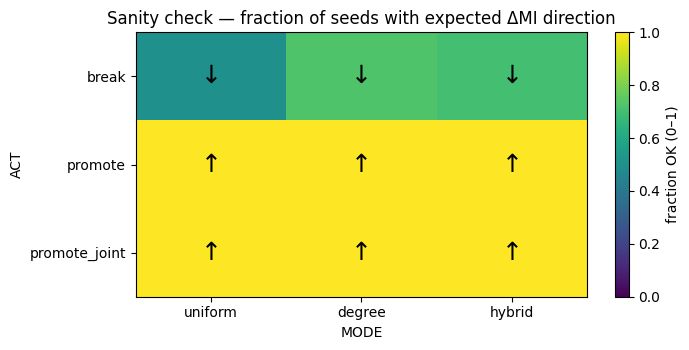

In [ ]:
plot_sanity_direction_consistency(dfB)


Sanity check: ref_intact all True? True


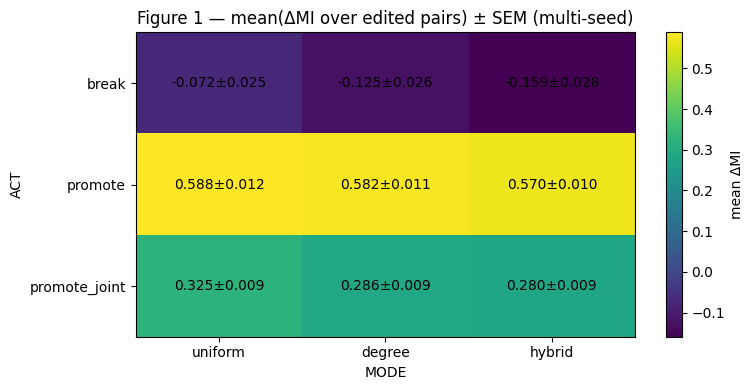

Resultados guardados en: /content/demo_B_multiseed


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- 1) Toy moderado (promote puede mejorar) ----------
def make_toy_msa_and_contacts_moderate(out_dir="demo_toyB", nseq=120, L=40, seed=0, p_corr=0.70):
    rng = np.random.default_rng(seed)
    os.makedirs(out_dir, exist_ok=True)

    aa = np.array(list("ACDEFGHIKLMNPQRSTVWY"))
    target_pair = (5, 30)  # 1-based

    # Mapeo “verdadero”
    map_AB = {"K": "E", "R": "D", "A": "A", "V": "V", "G": "G"}
    keys = np.array(list(map_AB.keys()))
    vals = np.array(list(map_AB.values()))

    headers, seqs = [], []
    for s in range(nseq):
        x = rng.choice(aa, size=L)

        a = rng.choice(keys)
        x[target_pair[0]-1] = a

        # 70% correlacionado, 30% “ruido” (random)
        if rng.random() < p_corr:
            x[target_pair[1]-1] = map_AB[str(a)]
        else:
            x[target_pair[1]-1] = rng.choice(aa)

        headers.append(f"toy_{s}")
        seqs.append("".join(x.tolist()))

    msa_path = os.path.join(out_dir, "toy.a3m")
    write_fasta(msa_path, headers, seqs)

    # CSV de contactos: hacemos hub en 5 + extras
    hub_i = target_pair[0]
    hub_partners = [12, 18, 22, 26, 30, 33, 35]
    extra_pairs = [(8, 20), (10, 27), (14, 37), (16, 25), (19, 36), (2, 39)]
    pairs = [(hub_i, j) for j in hub_partners] + extra_pairs

    # distancias para que "hybrid" exista
    dist = []
    for (i, j) in pairs:
        if (i, j) == target_pair or (j, i) == target_pair:
            dist.append(6.0)
        elif i == hub_i:
            dist.append(float(rng.uniform(7.0, 12.0)))
        else:
            dist.append(float(rng.uniform(9.0, 15.0)))

    contacts_path = os.path.join(out_dir, "toy_contacts.csv")
    pd.DataFrame({"resi1":[p[0] for p in pairs], "resi2":[p[1] for p in pairs], "dist_B":dist}).to_csv(contacts_path, index=False)

    ref_index = 0
    ref_seq = seqs[ref_index]
    return msa_path, contacts_path, ref_index, target_pair, ref_seq


# ---------- helpers lectura de resultados ----------
def _read_one_run(out_dir):
    summ = pd.read_csv(os.path.join(out_dir, "summary.csv"))
    tag = summ.loc[0, "tag"]
    rep = pd.read_csv(os.path.join(out_dir, f"report_{tag}.csv"))
    return tag, summ, rep

def _extract_pair_delta(rep_df, target_pair):
    ti, tj = target_pair
    tgt = (min(ti, tj), max(ti, tj))
    for _, row in rep_df.iterrows():
        s = str(row["pair"]).strip().strip("()")
        parts = [x.strip() for x in s.split(",")]
        if len(parts) != 2:
            continue
        try:
            a = int(parts[0]); b = int(parts[1])
        except:
            continue
        cur = (min(a, b), max(a, b))
        if cur == tgt:
            return float(row["delta_mi"]), float(row["mi_before"]), float(row["mi_after"])
    return None


# ---------- 2) Multi-seed experiment ----------
def run_multi_seed_demo_B(
    nseq=120, L=40, p_corr=0.70,
    pair_frac=0.20, strength=0.60,
    alpha=0.05, gamma=4.0,
    seeds=range(1, 41),          # 40 replicados (ajustá a gusto)
):
    demo_root = "demo_B_multiseed"
    toy_dir = os.path.join(demo_root, "toy_data")
    out_root = os.path.join(demo_root, "runs")
    os.makedirs(out_root, exist_ok=True)

    msa_path, contacts_csv, ref_index, target_pair, ref_before = make_toy_msa_and_contacts_moderate(
        out_dir=toy_dir, nseq=nseq, L=L, seed=0, p_corr=p_corr
    )

    actions = ["break", "promote", "promote_joint"]
    modes   = ["uniform", "degree", "hybrid"]

    records = []
    for action in actions:
        for mode in modes:
            for sd in seeds:
                run_out_dir = os.path.join(out_root, f"act-{action}__mode-{mode}__seed-{sd}")

                out_dir = make_progressive_msas_weighted(
                    msa_in_path=msa_path,
                    contacts_csv=contacts_csv,
                    base_out_dir=run_out_dir,
                    mode=mode,
                    pair_fracs=[pair_frac],
                    strength_grid=[strength],
                    seeds=[sd],
                    action=action,
                    ref_index=ref_index,
                    one_based=True,
                    alpha=alpha,
                    power_gamma=gamma,
                    min_seq_sep=0,
                    use_dist_filter=False,
                    max_dist_for_gain=None
                )

                tag, summ, rep = _read_one_run(out_dir)
                # % de pares editados con ΔMI > 0 en esta corrida
                deltas = rep["delta_mi"].astype(float).values
                pct_pos = float(np.mean(deltas > 0)) if len(deltas) else np.nan


                # mean ΔMI sobre pares elegidos
                dmi_mean = float(summ.loc[0, "delta_mi_mean"]) if not pd.isna(summ.loc[0, "delta_mi_mean"]) else np.nan

                # ref intacta (sanity)
                msa_out_path = os.path.join(out_dir, f"msa_{tag}.a3m")
                _, seqs_out = read_fasta_or_a3m(msa_out_path)
                ref_ok = (seqs_out[ref_index] == ref_before)

                records.append({
                    "action": action, "mode": mode, "seed": sd,
                    "delta_mi_mean_all": dmi_mean,
                    "pct_pos": pct_pos,
                    "ref_intact": ref_ok
                })

    df = pd.DataFrame(records)
    df.to_csv(os.path.join(demo_root, "all_results.csv"), index=False)
    return df, demo_root


# ---------- 3) Figuras 1 y 3 con media ± SEM ----------
def sem(x):
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    if len(x) <= 1:
        return np.nan
    return x.std(ddof=1) / np.sqrt(len(x))

def plot_fig1_heatmap(df):
    actions = ["break", "promote", "promote_joint"]
    modes   = ["uniform", "degree", "hybrid"]

    mean_piv = df.pivot_table(index="action", columns="mode", values="delta_mi_mean_all", aggfunc="mean").reindex(actions)[modes]
    sem_piv  = df.pivot_table(index="action", columns="mode", values="delta_mi_mean_all", aggfunc=sem).reindex(actions)[modes]

    fig = plt.figure(figsize=(7.8, 4.0))
    ax = plt.gca()
    im = ax.imshow(mean_piv.values, aspect="auto")

    ax.set_xticks(np.arange(len(modes))); ax.set_xticklabels(modes)
    ax.set_yticks(np.arange(len(actions))); ax.set_yticklabels(actions)
    ax.set_title("Figure 1 — mean(ΔMI over edited pairs) ± SEM (multi-seed)")
    ax.set_xlabel("MODE"); ax.set_ylabel("ACT")

    for i in range(len(actions)):
        for j in range(len(modes)):
            m = mean_piv.values[i, j]
            s = sem_piv.values[i, j]
            ax.text(j, i, f"{m:.3f}±{s:.3f}", ha="center", va="center")

    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label("mean ΔMI")
    plt.tight_layout()
    plt.show()


# ---------- RUN ----------
dfB, root = run_multi_seed_demo_B(
    nseq=120, L=40, p_corr=0.70,
    pair_frac=0.20, strength=0.60,
    alpha=0.05, gamma=4.0,
    seeds=range(1, 41)   # 40 seeds
)

print("Sanity check: ref_intact all True?", dfB["ref_intact"].all())
plot_fig1_heatmap(dfB)
print("Resultados guardados en:", os.path.abspath(root))


In [ ]:
import os

# =========================
# BLOQUE 1 — CORE FUNCTIONS (moved _fmt here for self-containment)
# =========================
def _fmt(x):
    if isinstance(x, float):
        s = f"{x:.3g}"
    else:
        s = str(x)
    return s.replace(".", "_")

# =========================
# BLOQUE 2 — SWEEP / BARRIDO
# =========================

MSA_IN_PATH   = "/content/MSA.a3m"
CONTACTS_CSV  = "/content/delta_contacts_lost_A_minus_B.csv"
BASE_OUT_DIR  = "msa_progressive_sweep_A_minus_B"
MASTER_DIR    = "all_runs_a3m_A_minus_B"

REF_INDEX = 0
ONE_BASED = True

ACTIONS        = ["promote_joint"]      # opcional: "break"
MODES          = ["degree"]                         # "uniform","dist","hybrid"
PAIR_FRACS     = [0.3, 0.6, 0.9]
STRENGTHS      = [0.3, 0.6, 0.9]
SEEDS          = [11, 22, 33]

ALPHAS         = [0.05, 0.1]
GAMMAS         = [2.0, 3.0, 4.0]

MIN_SEQ_SEPS   = [8, 12]
#USE_DIST_FILT  = [False]                           # si True, usá MAX_DISTS
#MAX_DISTS      = [8.0, 10.0]

os.makedirs(BASE_OUT_DIR, exist_ok=True)
os.makedirs(MASTER_DIR, exist_ok=True)

total_runs = 0
# for action in ACTIONS:
#     for mode in MODES:
#         for alpha in ALPHAS:
#             for gamma in GAMMAS:
#                 for min_sep in MIN_SEQ_SEPS:
#                     for use_df in USE_DIST_FILT:
#                         max_dist_list = MAX_DISTS if use_df else [None]

#                         for max_dist in max_dist_list:
#                             run_out_dir = os.path.join(
#                                 BASE_OUT_DIR,
#                                 f"run__act-{action}__mode-{mode}__a-{_fmt(alpha)}__g-{_fmt(gamma)}"
#                                 f"__minsep-{min_sep}__df-{int(bool(use_df))}"
#                                 + (f"__maxd-{_fmt(max_dist)}" if max_dist is not None else "")
#                             )

#                             out_dir = make_progressive_msas_weighted(
#                                 msa_in_path=MSA_IN_PATH,
#                                 contacts_csv=CONTACTS_CSV,
#                                 base_out_dir=run_out_dir,
#                                 mode=mode,
#                                 pair_fracs=PAIR_FRACS,
#                                 strength_grid=STRENGTHS,
#                                 seeds=SEEDS,
#                                 action=action,
#                                 ref_index=REF_INDEX,
#                                 one_based=ONE_BASED,
#                                 alpha=alpha,
#                                 power_gamma=gamma,
#                                 min_seq_sep=min_sep,
#                                 use_dist_filter=use_df,
#                                 max_dist_for_gain=max_dist
#                             )

                            # macro_suffix = (
                            #     f"__ACT-{action}"
                            #     f"__MODE-{mode}"
                            #     f"__A-{_fmt(alpha)}"
                            #     f"__G-{_fmt(gamma)}"
                            #     f"__MINSEP-{min_sep}"
                            #     f"__DF-{int(bool(use_df))}"
                            #     + (f"__MAXD-{_fmt(max_dist)}" if max_dist is not None else "")
                            # )

                            # copy_a3m_tree_to_master(
                            #     src_root=run_out_dir,
                            #     dst_root=MASTER_DIR,
                            #     extra_suffix=macro_suffix
                            # )

                            # total_runs += 1
                            # print(f"✔️ corrida OK → {macro_suffix}")




  # Simplified Sweep — No distance filters
for action in ACTIONS:
    for mode in MODES: # Stick to "uniform" or "degree"
        for alpha in ALPHAS:
            for gamma in GAMMAS:
                for min_sep in MIN_SEQ_SEPS:
                    # We remove the use_df and max_dist loops entirely
                    run_out_dir = os.path.join(
                        BASE_OUT_DIR,
                        f"run__act-{action}__mode-{mode}__a-{_fmt(alpha)}__g-{_fmt(gamma)}"
                        f"__minsep-{min_sep}"
                    )

                    out_dir = make_progressive_msas_weighted(
                        msa_in_path=MSA_IN_PATH,
                        contacts_csv=CONTACTS_CSV,
                        base_out_dir=run_out_dir,
                        mode=mode,
                        pair_fracs=PAIR_FRACS,
                        strength_grid=STRENGTHS,
                        seeds=SEEDS,
                        action=action,
                        ref_index=REF_INDEX,
                        one_based=ONE_BASED,
                        alpha=alpha,
                        power_gamma=gamma,
                        min_seq_sep=min_sep,
                        use_dist_filter=False, # Hardcoded to False
                        max_dist_for_gain=None  # Hardcoded to None
                    )

                    macro_suffix = (
                              f"__ACT-{action}"
                              f"__MODE-{mode}"
                              f"__A-{_fmt(alpha)}"
                              f"__G-{_fmt(gamma)}"
                              f"__MINSEP-{min_sep}"
                              f"__DF-{int(bool(use_df))}"
                              + (f"__MAXD-{_fmt(max_dist)}" if max_dist is not None else "")
                          )

                    copy_a3m_tree_to_master(
                        src_root=run_out_dir,
                        dst_root=MASTER_DIR,
                        extra_suffix=macro_suffix
                    )

                    total_runs += 1
                    print(f"✔️ corrida OK → {macro_suffix}")


print(f"\nListo. Corridas ejecutadas: {total_runs}")
print("Master:", os.path.abspath(MASTER_DIR))

NameError: name 'use_df' is not defined

## bloque que no usa las distancias ##

In [ ]:
import os

# =========================
# BLOQUE 1 — CORE FUNCTIONS (Keeping _fmt for self-containment)
# =========================
def _fmt(x):
    if isinstance(x, float):
        s = f"{x:.3g}"
    else:
        s = str(x)
    return s.replace(".", "_")

# =========================
# BLOQUE 2 — SWEEP / BARRIDO (Cleaned & Distance-Free)
# =========================

# --- Configuration Paths ---
MSA_IN_PATH   = "/content/MSA.a3m"
CONTACTS_CSV  = "/content/delta_contacts_gained_B_minus_A.csv"
BASE_OUT_DIR  = "msa_progressive_sweep_B_minus_A"
MASTER_DIR    = "all_runs_a3m_B_minus_A"

# --- MSA Parameters ---
REF_INDEX = 0
ONE_BASED = True

# --- Hyperparameters for the Sweep ---
ACTIONS        = ["promote_joint"]
MODES          = ["degree"]         # "uniform" or "degree" work best without distances
PAIR_FRACS     = [0.3, 0.6, 0.9]
STRENGTHS      = [0.3, 0.6, 0.9]
SEEDS          = [11, 22, 33]
ALPHAS         = [0.05, 0.1]
GAMMAS         = [2.0, 3.0, 4.0]
MIN_SEQ_SEPS   = [8, 12]

# Ensure directories exist
os.makedirs(BASE_OUT_DIR, exist_ok=True)
os.makedirs(MASTER_DIR, exist_ok=True)

total_runs = 0

# =========================
# EXECUTION LOOP
# =========================
for action in ACTIONS:
    for mode in MODES:
        for alpha in ALPHAS:
            for gamma in GAMMAS:
                for min_sep in MIN_SEQ_SEPS:

                    # 1. Define folder name (Removed distance flags)
                    run_name = (
                        f"run__act-{action}__mode-{mode}"
                        f"__a-{_fmt(alpha)}__g-{_fmt(gamma)}"
                        f"__minsep-{min_sep}"
                    )
                    run_out_dir = os.path.join(BASE_OUT_DIR, run_name)

                    # 2. Run the experiment
                    # We pass use_dist_filter=False because you don't need them
                    out_dir = make_progressive_msas_weighted(
                        msa_in_path=MSA_IN_PATH,
                        contacts_csv=CONTACTS_CSV,
                        base_out_dir=run_out_dir,
                        mode=mode,
                        pair_fracs=PAIR_FRACS,
                        strength_grid=STRENGTHS,
                        seeds=SEEDS,
                        action=action,
                        ref_index=REF_INDEX,
                        one_based=ONE_BASED,
                        alpha=alpha,
                        power_gamma=gamma,
                        min_seq_sep=min_sep,
                        use_dist_filter=False,
                        max_dist_for_gain=None
                    )

                    # 3. Create a unique suffix for the files in the Master folder
                    macro_suffix = (
                        f"__ACT-{action}"
                        f"__MODE-{mode}"
                        f"__A-{_fmt(alpha)}"
                        f"__G-{_fmt(gamma)}"
                        f"__MINSEP-{min_sep}"
                    )

                    # 4. Copy generated A3Ms to the Master Directory
                    copy_a3m_tree_to_master(
                        src_root=run_out_dir,
                        dst_root=MASTER_DIR,
                        extra_suffix=macro_suffix
                    )

                    total_runs += 1
                    print(f"✔️ Run {total_runs} OK → {macro_suffix}")

print(f"\nDone! Total runs executed: {total_runs}")
print("Master Directory:", os.path.abspath(MASTER_DIR))

✔️ Run 1 OK → __ACT-promote_joint__MODE-degree__A-0_05__G-2__MINSEP-8
✔️ Run 2 OK → __ACT-promote_joint__MODE-degree__A-0_05__G-2__MINSEP-12
✔️ Run 3 OK → __ACT-promote_joint__MODE-degree__A-0_05__G-3__MINSEP-8
✔️ Run 4 OK → __ACT-promote_joint__MODE-degree__A-0_05__G-3__MINSEP-12
✔️ Run 5 OK → __ACT-promote_joint__MODE-degree__A-0_05__G-4__MINSEP-8
✔️ Run 6 OK → __ACT-promote_joint__MODE-degree__A-0_05__G-4__MINSEP-12
✔️ Run 7 OK → __ACT-promote_joint__MODE-degree__A-0_1__G-2__MINSEP-8
✔️ Run 8 OK → __ACT-promote_joint__MODE-degree__A-0_1__G-2__MINSEP-12
✔️ Run 9 OK → __ACT-promote_joint__MODE-degree__A-0_1__G-3__MINSEP-8
✔️ Run 10 OK → __ACT-promote_joint__MODE-degree__A-0_1__G-3__MINSEP-12
✔️ Run 11 OK → __ACT-promote_joint__MODE-degree__A-0_1__G-4__MINSEP-8
✔️ Run 12 OK → __ACT-promote_joint__MODE-degree__A-0_1__G-4__MINSEP-12

Done! Total runs executed: 12
Master Directory: /content/all_runs_a3m_B_minus_A


In [ ]:
import shutil
from google.colab import files

# CHANGE THIS:
folder_path = "/content/all_runs_a3m_B_minus_A"   # folder you want to download
zip_path = "/content/all_runs_a3m_B_minus_A.zip"  # output zip name

# Create zip (no ".zip" at the end in make_archive base name)
shutil.make_archive(zip_path.replace(".zip",""), 'zip', folder_path)

# Download to your local computer
files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## GENERAMOS LAS ESTRUCTURAS CON BOLTZ ##

--> para cada MSA generado obtenemos una estructura y un embedding

## ANALIZAMOS LOS RESULTADOS ##

qqplot:


Se encontraron 1076 estructuras:
 - query_msa_hybrid_frac1.00_str1.00_seed42__g0_5_s1_0_model_0.cif
 - query_msa_hybrid_frac0.80_str1.00_seed42__g2_5_s1_0_model_0.cif
 - query_msa_hybrid_frac0.60_str0.80_seed42__g3_s0_8_model_0.cif
 - query_msa_hybrid_frac0.60_str0.40_seed42__g2_s1_0_model_0.cif
 - query_msa_hybrid_frac0.60_str0.80_seed42__g2_5_s1_0_model_0.cif
 - query_msa_hybrid_frac0.40_str1.00_seed42__g1_s1_0_model_0.cif
 - query_msa_hybrid_frac0.20_str1.00_seed42__g2_5_s1_0_model_0.cif
 - query_msa_hybrid_frac1.00_str1.00_seed42__g0_s0_2_model_0.cif
 - query_msa_hybrid_frac0.20_str1.00_seed42__g3_s1_0_model_0.cif
 - query_msa_hybrid_frac1.00_str0.80_seed42__g5_s1_0_model_0.cif
 - query_msa_hybrid_frac0.60_str0.20_seed42__g0_s0_2_model_0.cif
 - query_msa_hybrid_frac0.40_str0.40_seed42__g2_5_s1_0_model_0.cif
 - query_msa_hybrid_frac0.40_str1.00_seed42__g2_5_s1_0_model_0.cif
 - query_msa_hybrid_frac0.80_str1.00_seed42__g0_s1_0_model_0.cif
 - query_msa_hybrid_frac0.40_str0.40_seed42_

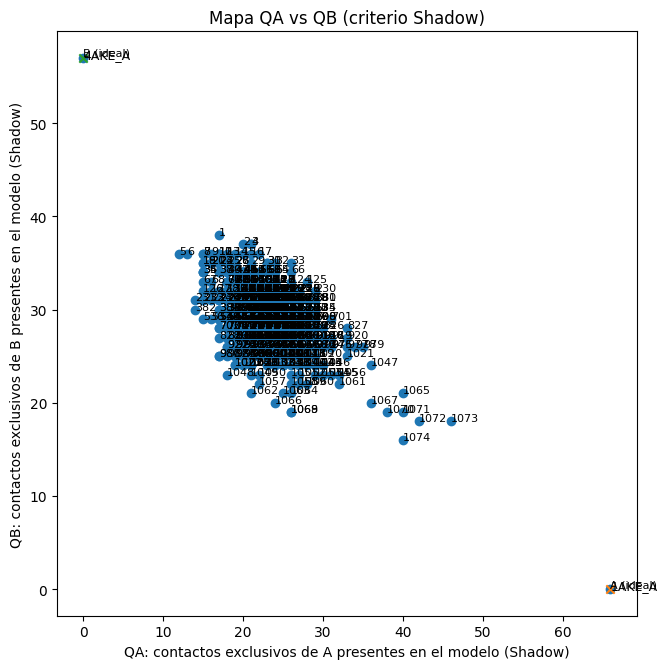

Etiquetado OK. Archivos guardados:
 - /content/drive/MyDrive/laboratorio_alphafold/test_boltz_2/results_contactos_shadow/QA_vs_QB_shadow.png
 - /content/drive/MyDrive/laboratorio_alphafold/test_boltz_2/results_contactos_shadow/legend_QA_QB_numbers.csv (número -> modelo para los no-referencia)


In [ ]:
# -*- coding: utf-8 -*-
"""
Pipeline automático para calcular contactos "Shadow" (átomos pesados + oclusión)
a partir de múltiples estructuras .cif/.pdb, comparar contactos entre
dos conformaciones de referencia (A y B), y generar un gráfico QA vs QB.

Criterio Shadow:
- CUTOFF C (Å) para vecinos átomo–átomo.
- Se descartan si hay un átomo intermedio cuya distancia al segmento <= S (Å).
- Se excluyen vecinos 1–2 y 1–3 en la misma cadena (MIN_SEQ_SEP=3).
- Se trabaja a nivel residuo–residuo (pares únicos normalizados).
"""

# ===========================================================
# ✅ CONFIGURACIÓN
# ===========================================================
from Bio.PDB import MMCIFParser, PDBParser, is_aa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
from scipy.spatial import cKDTree as KDTree

# --- Rutas / carpetas ---
PROJECT_DIR = "/content/drive/MyDrive/laboratorio_alphafold/test_boltz_2"
STRUCTURES_DIR = os.path.join(PROJECT_DIR, "all_structures")
RESULTS_DIR = os.path.join(PROJECT_DIR, "results_contactos_shadow")
os.makedirs(RESULTS_DIR, exist_ok=True)

# --- Modelos de referencia (cerrada / abierta) ---
REFERENCE_A = "1AKE_A.pdb"
REFERENCE_B = "4AKE_A.pdb"

# --- Parámetros Shadow ---
CUTOFF = 5.2          # C (Å) - vecindad átomo–átomo
SHADOW_S = 1.3        # S (Å) - radio de "sombreado" para oclusión
MIN_SEQ_SEP = 3       # excluir 1–2 y 1–3 (|Δseq| <= 2)
CHAIN_ID = None       # "A" para restringir, None = todas
ALLOW_INTERCHAINS = False
EXCLUDE_WATER = True

# ===========================================================
# ✅ FUNCIONES DE E/S
# ===========================================================
def load_structure(path):
    """Carga estructura con Bio.Python, soporta .cif y .pdb. Devuelve el primer modelo."""
    ext = os.path.splitext(path)[1].lower()
    parser = MMCIFParser(QUIET=True) if ext == ".cif" else PDBParser(QUIET=True)
    try:
        structure = parser.get_structure("model", path)
        return structure[0]
    except Exception as e:
        print(f"Error loading structure {path}: {e}")
        return None

def is_heavy(atom):
    """Excluye H/D/T si aparecieran."""
    el = (atom.element or "").upper()
    if not el:
        # fallback por nombre
        name = atom.get_name().strip()
        el = "".join([c for c in name if c.isalpha()])[:1].upper()
    return el not in {"H", "D", "T"}

# ===========================================================
# ✅ UTILIDADES GEOMÉTRICAS (Shadow)
# ===========================================================
def point_segment_distance(p, a, b):
    """Distancia de p al segmento ab y parámetro t (proyección)."""
    ab = b - a
    ap = p - a
    ab2 = float(np.dot(ab, ab))
    if ab2 == 0.0:
        return float(np.linalg.norm(ap)), 0.0
    t = max(0.0, min(1.0, float(np.dot(ap, ab) / ab2)))
    proj = a + t * ab
    return float(np.linalg.norm(p - proj)), t

# ===========================================================
# ✅ EXTRACCIÓN DE ÁTOMOS Y ORDEN SECUENCIAL
# ===========================================================
def chain_ok(chain_id):
    return True if CHAIN_ID is None else (chain_id == CHAIN_ID)

def harvest_heavy_atoms(model):
    """
    Recolecta átomos pesados por residuo e índice secuencial por cadena.
    Devuelve:
    - atoms: lista de dicts con info y coords
    - res_order: (chain, resseq, icode) -> índice secuencial
    """
    # construir orden de residuos por cadena
    res_order = {}
    for ch in model:
        if not chain_ok(ch.id):
            continue
        residues = [r for r in ch if (not EXCLUDE_WATER or r.id[0] != "W") and is_aa(r, standard=True)]
        residues.sort(key=lambda r: (r.id[1], r.id[2] or " "))
        for i, r in enumerate(residues):
            key = (ch.id, r.id[1], r.id[2] or " ")
            res_order[key] = i

    atoms = []
    idx = 0
    for ch in model:
        if not chain_ok(ch.id):
            continue
        for r in ch:
            if EXCLUDE_WATER and r.id[0] == "W":
                continue
            if not is_aa(r, standard=True):
                continue
            key = (ch.id, r.id[1], r.id[2] or " ")
            seq_index = res_order.get(key, None)
            for a in r:
                if not is_heavy(a):
                    continue
                atoms.append(dict(
                    idx=idx,
                    chain=ch.id,
                    resname=r.get_resname(),
                    resseq=r.id[1],
                    icode=r.id[2] or " ",
                    atom=a.get_name().strip(),
                    is_backbone=a.get_name().strip() in {"N","CA","C","O","OXT"},
                    coord=a.get_coord().astype(float),
                    seq_index=seq_index
                ))
                idx += 1
    return atoms, res_order

def normalize_res_pair(p):
    """Normaliza un par de residuos a una tupla ordenada estable para usar en sets/dicts."""
    (ci, ri, ii), (cj, rj, ij) = p
    a = (ci, int(ri), str(ii))
    b = (cj, int(rj), str(ij))
    return tuple(sorted([a, b]))

# ===========================================================
# ✅ CONTACTOS SHADOW (RESIDUO–RESIDUO)
# ===========================================================
def shadow_contacts_residue(model, C=CUTOFF, S=SHADOW_S,
                            min_seq_sep=MIN_SEQ_SEP,
                            allow_interchains=ALLOW_INTERCHAINS):
    """
    Calcula contactos residuo–residuo con criterio Shadow.
    Devuelve: set de pares ((chain_i, res_i, icode_i), (chain_j, res_j, icode_j))
    """
    atoms, _ = harvest_heavy_atoms(model)
    if not atoms:
        return set()

    coords = np.vstack([a["coord"] for a in atoms])
    tree = KDTree(coords)

    res_pairs = set()

    for i, ai in enumerate(atoms):
        # buscar vecinos candidatos en radio C
        neigh = tree.query_ball_point(ai["coord"], C)
        for j in neigh:
            if j <= i:
                continue
            aj = atoms[j]

            # filtro inter-cadenas
            if not allow_interchains and ai["chain"] != aj["chain"]:
                continue

            # excluir 1–2 y 1–3 (misma cadena)
            if ai["chain"] == aj["chain"] and ai["seq_index"] is not None and aj["seq_index"] is not None:
                if abs(ai["seq_index"] - aj["seq_index"]) <= (min_seq_sep - 1):
                    continue

            # distancia real
            d = float(np.linalg.norm(ai["coord"] - aj["coord"]))
            if d > C or d <= 1e-6:
                continue

            # candidatos para oclusión: esfera alrededor del punto medio
            midpoint = 0.5 * (ai["coord"] + aj["coord"])
            search_r = 0.5 * d + S
            cand = tree.query_ball_point(midpoint, search_r)

            # Ajuste conservador: si son casi secuenciales (p. ej., 1–4), reducir S
            S_eff = S
            if ai["chain"] == aj["chain"] and ai["seq_index"] is not None and aj["seq_index"] is not None:
                if abs(ai["seq_index"] - aj["seq_index"]) == min_seq_sep:
                    S_eff = min(S, 0.5)

            # test de sombra: existe k que ocluye?
            A = ai["coord"]; B = aj["coord"]
            shadowed = False
            for k in cand:
                if k == i or k == j:
                    continue
                P = coords[int(k)]
                # prune rápido por cercanía a extremos
                if np.linalg.norm(P - A) >= d and np.linalg.norm(P - B) >= d:
                    continue
                dist, t = point_segment_distance(P, A, B)
                if dist <= S_eff and 0.0 <= t <= 1.0:
                    shadowed = True
                    break
            if shadowed:
                continue

            # si pasó el filtro, agregar par residuo–residuo
            pair = normalize_res_pair((
                (ai["chain"], ai["resseq"], ai["icode"]),
                (aj["chain"], aj["resseq"], aj["icode"])
            ))
            res_pairs.add(pair)

    return res_pairs

def compute_contact_sets(structure_path):
    model = load_structure(structure_path)
    if model is None:
        return set()
    return shadow_contacts_residue(model, C=CUTOFF, S=SHADOW_S,
                                   min_seq_sep=MIN_SEQ_SEP,
                                   allow_interchains=ALLOW_INTERCHAINS)

# ===========================================================
# ✅ CÁLCULO DE CONTACTOS EN LOTE
# ===========================================================
all_files = [f for f in os.listdir(STRUCTURES_DIR) if f.lower().endswith((".cif", ".pdb"))]
print(f"\nSe encontraron {len(all_files)} estructuras:")
for f in all_files:
    print(" -", f)

contacts_dict = {}
for i, fname in enumerate(sorted(all_files), 1):
    path = os.path.join(STRUCTURES_DIR, fname)
    print(f"\n[{i}/{len(all_files)}] Procesando {fname} ...", end=" ")
    contacts = compute_contact_sets(path)
    print(f"{len(contacts)} contactos residuo–residuo (Shadow).")
    contacts_dict[fname] = contacts

# ===========================================================
# ✅ DELTA-CONTACTOS Y QA/QB
# ===========================================================
if REFERENCE_A not in contacts_dict or REFERENCE_B not in contacts_dict:
    raise KeyError(
        f"Las referencias no están entre las estructuras cargadas.\n"
        f"REFERENCE_A={REFERENCE_A}\nREFERENCE_B={REFERENCE_B}\n"
        f"Claves disponibles: {list(contacts_dict.keys())}"
    )

A = contacts_dict[REFERENCE_A]
B = contacts_dict[REFERENCE_B]
A_only = A - B
B_only = B - A
print(f"\nContactos exclusivos de A: {len(A_only)} | exclusivos de B: {len(B_only)}")

# Guardar conjuntos A_only/B_only para inspección
def pairs_to_df(pairs):
    rows = []
    for (ci, ri, ii), (cj, rj, ij) in pairs:
        rows.append(dict(chain_i=ci, res_i=ri, icode_i=ii, chain_j=cj, res_j=rj, icode_j=ij))
    return pd.DataFrame(rows)

pairs_to_df(A_only).to_csv(os.path.join(RESULTS_DIR, "A_only_pairs.csv"), index=False)
pairs_to_df(B_only).to_csv(os.path.join(RESULTS_DIR, "B_only_pairs.csv"), index=False)

rows = []
for fname, contacts in contacts_dict.items():
    QA = len(contacts & A_only)
    QB = len(contacts & B_only)
    QA_frac = QA / len(A_only) if len(A_only) else float("nan")
    QB_frac = QB / len(B_only) if len(B_only) else float("nan")
    rows.append(dict(
        model_label=os.path.splitext(fname)[0],
        qa=QA, qb=QB,
        qa_frac=QA_frac, qb_frac=QB_frac,
        total_contacts=len(contacts)
    ))

summary = pd.DataFrame(rows).sort_values(["qb", "qa"], ascending=[False, True])
summary_path = os.path.join(RESULTS_DIR, "QA_QB_summary_shadow.csv")
summary.to_csv(summary_path, index=False)

print("\nResumen QA/QB por modelo:")
print(summary.to_string(index=False))

# ===========================================================
# ✅ GRÁFICO QA vs QB (solo 1AKE_A y 4AKE_A con nombre; resto numeradas)
# ===========================================================
import os

plt.figure(figsize=(6.8, 6.8))
plt.scatter(summary["qa"], summary["qb"])

# Identificadores base (sin extensión) de las referencias
ref_a = os.path.splitext(REFERENCE_A)[0]
ref_b = os.path.splitext(REFERENCE_B)[0]

# Asignar números SOLO a los no-referencia en el orden en que aparecen en el scatter (summary)
num_map = {}   # model_label -> número
counter = 1
for _, r in summary.iterrows():
    label = r["model_label"]
    if label not in {ref_a, ref_b}:
        num_map[label] = counter
        counter += 1

# Etiquetado: refs por nombre, resto por número
for _, r in summary.iterrows():
    x, y = float(r["qa"]), float(r["qb"])
    label = r["model_label"]
    if label in {ref_a, ref_b}:
        plt.text(x, y, label, fontsize=9)
    else:
        plt.text(x, y, str(num_map[label]), fontsize=8)

plt.xlabel("QA: contactos exclusivos de A presentes en el modelo (Shadow)")
plt.ylabel("QB: contactos exclusivos de B presentes en el modelo (Shadow)")
plt.title("Mapa QA vs QB (criterio Shadow)")

# Puntos “ideal” A y B
plt.scatter([len(A_only)], [0], marker="x")
plt.text(len(A_only), 0, "A (ideal)", fontsize=8, ha="left", va="bottom")
plt.scatter([0], [len(B_only)], marker="x")
plt.text(0, len(B_only), "B (ideal)", fontsize=8, ha="left", va="bottom")

plt.tight_layout()
plot_path = os.path.join(RESULTS_DIR, "QA_vs_QB_shadow.png")
plt.savefig(plot_path, dpi=150)
plt.show()

# Guardar leyenda de números → modelos (excluye referencias)
legend_rows = [
    {"number": n, "model_label": lbl}
    for lbl, n in sorted(num_map.items(), key=lambda x: x[1])
]
legend_df = pd.DataFrame(legend_rows)
legend_path = os.path.join(RESULTS_DIR, "legend_QA_QB_numbers.csv")
legend_df.to_csv(legend_path, index=False)

print("Etiquetado OK. Archivos guardados:")
print(" -", plot_path)
print(" -", legend_path, "(número -> modelo para los no-referencia)")


PCA

Referencia: 4AKE_A.pdb | Cα: 214

Alineando y extrayendo Cα:
 - query_msa_hybrid_frac0.80_str1.00_seed42__g2_5_s1_0_model_0.cif: alineado (RMSD=7.750 Å)
 - query_msa_hybrid_frac0.60_str0.80_seed42__g3_s0_8_model_0.cif: alineado (RMSD=8.200 Å)
 - query_msa_hybrid_frac0.60_str0.40_seed42__g2_s1_0_model_0.cif: alineado (RMSD=8.070 Å)
 - query_msa_hybrid_frac0.60_str0.80_seed42__g2_5_s1_0_model_0.cif: alineado (RMSD=8.591 Å)
 - query_msa_hybrid_frac0.40_str1.00_seed42__g1_s1_0_model_0.cif: alineado (RMSD=8.075 Å)
 - query_msa_hybrid_frac0.20_str1.00_seed42__g2_5_s1_0_model_0.cif: alineado (RMSD=8.116 Å)
 - query_msa_hybrid_frac1.00_str1.00_seed42__g0_s0_2_model_0.cif: alineado (RMSD=8.309 Å)
 - query_msa_hybrid_frac0.20_str1.00_seed42__g3_s1_0_model_0.cif: alineado (RMSD=8.119 Å)
 - query_msa_hybrid_frac1.00_str0.80_seed42__g5_s1_0_model_0.cif: alineado (RMSD=8.438 Å)
 - query_msa_hybrid_frac0.60_str0.20_seed42__g0_s0_2_model_0.cif: alineado (RMSD=8.104 Å)
 - query_msa_hybrid_frac0.40_str0

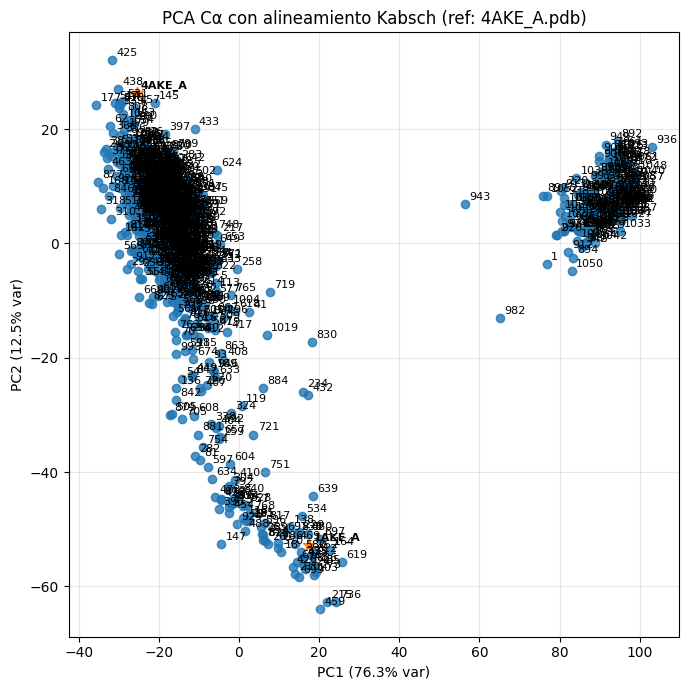

 - pca_label_map.csv


In [ ]:
# -*- coding: utf-8 -*-
"""
PCA estructural (Cα) con alineamiento rígido previo (Kabsch) usando Bio.PDB.Superimposer.
Lee .pdb/.cif desde STRUCTURES_DIR, alinea todo a la referencia y proyecta PC1–PC2.
Guarda además el RMSD de superposición a la referencia.
"""

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from Bio.PDB import PDBParser, MMCIFParser, is_aa, Superimposer

# ===========================================================
# ✅ CONFIGURACIÓN
# ===========================================================
PROJECT_DIR    = "/content/drive/MyDrive/laboratorio_alphafold/test_boltz_2"
STRUCTURES_DIR = os.path.join(PROJECT_DIR, "all_structures")
RESULTS_DIR    = os.path.join(PROJECT_DIR, "results_pca_2")
os.makedirs(RESULTS_DIR, exist_ok=True)

# Antes: CHAIN_ID = "A"
REFERENCE = "4AKE_A.pdb"   # podés cambiar la referencia si querés

# ===========================================================
# ✅ FUNCIONES AUXILIARES
# ===========================================================
def load_structure_generic(path):
    """Carga .pdb o .cif según extensión y retorna el primer modelo."""
    ext = os.path.splitext(path)[1].lower()
    parser = MMCIFParser(QUIET=True) if ext == ".cif" else PDBParser(QUIET=True)
    structure = parser.get_structure("model", path)
    return structure[0]

def get_main_chain(model):
    """
    Devuelve la cadena proteica 'principal'.
    Como todas tus estructuras tienen una sola cadena, en la práctica será esa,
    pero por robustez se elige la cadena con más residuos estándar.
    """
    chains = list(model.get_chains())
    if not chains:
        return None

    def count_std_res(chain):
        return sum(1 for r in chain if r.id[0] == " " and is_aa(r, standard=True))

    return max(chains, key=count_std_res)

def get_ca_atoms(model):
    """
    Lista de átomos CA (orden de recorrido) para la cadena principal.
    No depende del nombre de la cadena (A, 4AKE, etc.).
    """
    atoms = []
    chain = get_main_chain(model)
    if chain is None:
        return atoms
    for res in chain:
        if res.id[0] == " " and "CA" in res and is_aa(res, standard=True):
            atoms.append(res["CA"])
    return atoms

def coords_from_atoms(atoms):
    """np.array (N,3) a partir de lista de átomos."""
    return np.array([a.get_coord() for a in atoms], dtype=float)

def superimpose_to_ref(mobile_model, ref_model):
    """
    Alinea 'mobile_model' a 'ref_model' con Kabsch usando Cα.
    Modifica el 'mobile_model' in-place. Devuelve RMSD (float) o None si no pudo.
    """
    ref_atoms = get_ca_atoms(ref_model)
    mob_atoms = get_ca_atoms(mobile_model)
    if len(ref_atoms) == 0 or len(mob_atoms) == 0 or len(ref_atoms) != len(mob_atoms):
        return None
    sup = Superimposer()
    sup.set_atoms(ref_atoms, mob_atoms)
    sup.apply(mobile_model.get_atoms())
    return float(sup.rms)

# ===========================================================
# ✅ CARGA REFERENCIA
# ===========================================================
files = [f for f in os.listdir(STRUCTURES_DIR) if f.lower().endswith((".pdb", ".cif"))]
assert len(files) > 0, "No se encontraron estructuras en STRUCTURES_DIR"

ref_path = os.path.join(STRUCTURES_DIR, REFERENCE) if REFERENCE in files else os.path.join(STRUCTURES_DIR, files[0])
ref_model = load_structure_generic(ref_path)
ref_cas = get_ca_atoms(ref_model)
n_ref = len(ref_cas)
if n_ref == 0:
    raise ValueError(
        f"La referencia {os.path.basename(ref_path)} no tiene Cα estándar en su cadena proteica principal."
    )

print(f"Referencia: {os.path.basename(ref_path)} | Cα: {n_ref}")

# ===========================================================
# ✅ ALINEAMIENTO + EXTRACCIÓN DE COORDENADAS
# ===========================================================
X = []            # matriz (n_structures × 3N)
labels = []       # nombres para cada estructura
rmsds = []        # RMSD de alineamiento vs referencia

print("\nAlineando y extrayendo Cα:")
for f in files:
    path = os.path.join(STRUCTURES_DIR, f)
    try:
        model = load_structure_generic(path)

        # skip si no coincide el número de Cα
        if len(get_ca_atoms(model)) != n_ref:
            print(f" ⚠️ {f}: Nº de Cα distinto a la referencia. Se omite.")
            continue

        rms = superimpose_to_ref(model, ref_model)
        if rms is None:
            print(f" ⚠️ {f}: No se pudo alinear (longitudes distintas). Se omite.")
            continue

        ca_coords = coords_from_atoms(get_ca_atoms(model))  # ya alineadas
        X.append(ca_coords.flatten())
        labels.append(os.path.splitext(f)[0])
        rmsds.append(rms)
        print(f" - {f}: alineado (RMSD={rms:.3f} Å)")
    except Exception as e:
        print(f" ⚠️ {f}: error {e}. Se omite.")

if len(X) < 2:
    raise RuntimeError("Necesito al menos 2 estructuras alineadas para hacer PCA.")

X = np.vstack(X)  # (m × 3N)

# ===========================================================
# ✅ PCA (hasta 3 componentes)
# ===========================================================
n_comps = min(3, X.shape[0], X.shape[1])  # no más de 3, ni más de muestras o dims

try:
    from sklearn.decomposition import PCA
    pca = PCA(n_components=n_comps)
    proj = pca.fit_transform(X)  # (m × n_comps)
    var_ratio = pca.explained_variance_ratio_
except Exception:
    # Fallback SVD
    Xc = X - X.mean(axis=0, keepdims=True)
    U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
    n_comps = min(n_comps, U.shape[1])
    proj = U[:, :n_comps] * S[:n_comps]
    var = (S**2) / (X.shape[0]-1)
    var_ratio = (var / var.sum())[:n_comps]

# Aseguramos columnas PC1..PC3 si existen
cols = {"model": labels, "RMSD_to_ref": rmsds}
for i in range(n_comps):
    cols[f"PC{i+1}"] = proj[:, i]

df_proj = pd.DataFrame(cols).sort_values("model").reset_index(drop=True)
df_proj.to_csv(os.path.join(RESULTS_DIR, "pca_projection_kabsch.csv"), index=False)

# === Etiquetado: 1AKE_A y 4AKE_A por nombre; el resto numerado ===
SPECIAL = {"1AKE_A", "4AKE_A"}   # sin extensión, coincide con df_proj["model"]

display_labels = []
number_map = []   # para guardar el mapeo número -> modelo
counter = 1
for name in df_proj["model"]:
    if name in SPECIAL:
        display_labels.append(name)
    else:
        display_labels.append(str(counter))
        number_map.append((counter, name))
        counter += 1

df_proj["display"] = display_labels

# Guardar mapeo números → nombres (solo los no especiales)
if number_map:
    map_df = pd.DataFrame(number_map, columns=["label_number", "model"])
    map_df.to_csv(os.path.join(RESULTS_DIR, "pca_label_map.csv"), index=False)

# Guardamos varianzas (si existen)
var1 = float(var_ratio[0]) if n_comps >= 1 else None
var2 = float(var_ratio[1]) if n_comps >= 2 else None
var3 = float(var_ratio[2]) if n_comps >= 3 else None

print("\nVarianza explicada:")
for i in range(n_comps):
    print(f"PC{i+1}: {var_ratio[i]*100:.2f}%")

# ===========================================================
# ✅ GRÁFICO PC1–PC2 (con nombres para 1AKE_A/4AKE_A y números para el resto)
# ===========================================================
plt.figure(figsize=(7, 7))

is_special = df_proj["model"].isin(SPECIAL)
# puntos no especiales
plt.scatter(df_proj.loc[~is_special, "PC1"], df_proj.loc[~is_special, "PC2"], alpha=0.8)
# puntos especiales resaltados
plt.scatter(df_proj.loc[is_special, "PC1"], df_proj.loc[is_special, "PC2"], s=80, marker="*", zorder=3)

# Anotaciones
for _, r in df_proj.iterrows():
    txt = r["display"]
    kws = dict(xytext=(3, 3), textcoords="offset points", fontsize=8)
    if r["model"] in SPECIAL:
        kws.update(fontweight="bold")
    plt.annotate(txt, (r["PC1"], r["PC2"]), **kws)

plt.xlabel(f"PC1 ({var1*100:.1f}% var)")
plt.ylabel(f"PC2 ({var2*100:.1f}% var)")
plt.title(f"PCA Cα con alineamiento Kabsch (ref: {os.path.basename(ref_path)})")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "pca_projection_kabsch.png"), dpi=150)
plt.show()

print(" - pca_label_map.csv")


Total estructuras: 1077
Ruido: 171  |  No ruido: 906
Ejemplos ruido: ['query_msa_broken_frac0.20_str1.00_seed11_model_0', 'query_msa_broken_frac0.40_str1.00_seed11_model_0', 'query_msa_broken_frac0.60_str1.00_seed22_model_0', 'query_msa_degree_frac0.20_str1.00_seed42_model_0', 'query_msa_degree_frac0.40_str1.00_seed42_model_0', 'query_msa_gainF0.40_lossF0.40_gStr1.00_lStr1.00_seed42_model_0', 'query_msa_hybrid_frac0.20_str0.20_seed42__g0_s0_2_model_0', 'query_msa_hybrid_frac0.20_str0.80_seed42__g0_s0_2_model_0']
Ejemplos no ruido: ['1AKE_A', '4AKE_A', 'query_msa_degree_frac0.20_str0.40_seed11__ACT-promote__MODE-degree__A-0_05__G-2__MINSEP-12__DF-0_model_0', 'query_msa_degree_frac0.20_str0.40_seed11__ACT-promote__MODE-degree__A-0_05__G-2__MINSEP-8__DF-0_model_0', 'query_msa_degree_frac0.20_str0.40_seed11__ACT-promote__MODE-degree__A-0_05__G-3__MINSEP-12__DF-0_model_0', 'query_msa_degree_frac0.20_str0.40_seed11__ACT-promote__MODE-degree__A-0_05__G-3__MINSEP-8__DF-0_model_0', 'query_msa_d

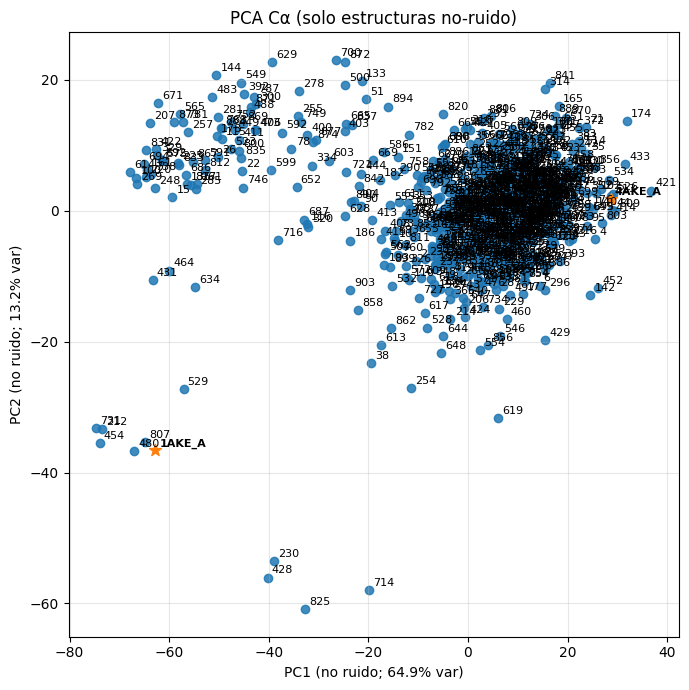


Listas guardadas en:
 - lista_ruido.txt / .csv
 - lista_no_ruido.txt / .csv
PCA no-ruido:
 - pca_projection_kabsch_NO_RUIDO.csv
 - pca_label_map_NO_RUIDO.csv (si hay numerados)
 - /content/drive/MyDrive/laboratorio_alphafold/test_boltz_2/results_pca_2/pca_projection_kabsch_NO_RUIDO_PC12.png


In [ ]:
# ===========================================================
# 🔎 Filtrado por "ruido" en PC1 y PCA solo con las no-ruido
#    - Ruido:    -100 <= PC1 <= -40
#    - Exporta listas y rehace PCA con las no-ruido
#    - Grafica solo PC1 vs PC2
# ===========================================================

# --- 1) Marcar ruido según PC1 ---
mask_ruido = df_proj["PC1"].between(40, 150, inclusive="both")
model_ruido    = df_proj.loc[mask_ruido, "model"].tolist()
model_no_ruido = df_proj.loc[~mask_ruido, "model"].tolist()

# Guardar listas
pd.Series(model_ruido).to_csv(os.path.join(RESULTS_DIR, "lista_ruido.txt"),
                              index=False, header=False)
pd.Series(model_no_ruido).to_csv(os.path.join(RESULTS_DIR, "lista_no_ruido.txt"),
                                 index=False, header=False)
pd.DataFrame({"ruido": model_ruido}).to_csv(os.path.join(RESULTS_DIR, "lista_ruido.csv"), index=False)
pd.DataFrame({"no_ruido": model_no_ruido}).to_csv(os.path.join(RESULTS_DIR, "lista_no_ruido.csv"), index=False)

print(f"Total estructuras: {len(df_proj)}")
print(f"Ruido: {len(model_ruido)}  |  No ruido: {len(model_no_ruido)}")
print("Ejemplos ruido:", model_ruido[:8])
print("Ejemplos no ruido:", model_no_ruido[:8])

# --- 2) Rehacer PCA SOLO con las no-ruido ---
# Importante: df_proj está ordenado alfabéticamente, pero X/labels están en el orden original.
# Construimos un reordenamiento para alinear X con df_proj:
model_to_idx = {m: i for i, m in enumerate(labels)}    # labels viene de arriba
order_idx = [model_to_idx[m] for m in df_proj["model"]] # X en el orden de df_proj
X_sorted = X[order_idx, :]

# Seleccionamos solo no-ruido
X_clean = X_sorted[~mask_ruido.values, :]
models_clean = df_proj.loc[~mask_ruido, "model"].tolist()

if X_clean.shape[0] < 2:
    raise RuntimeError("Quedaron menos de 2 estructuras no-ruido: no se puede rehacer el PCA.")

# PCA 2D (sklearn si está; si no, SVD)
try:
    from sklearn.decomposition import PCA
    pca_clean = PCA(n_components=2)
    proj_clean = pca_clean.fit_transform(X_clean)
    var1_c, var2_c = pca_clean.explained_variance_ratio_[0], pca_clean.explained_variance_ratio_[1]
except Exception:
    Xc2 = X_clean - X_clean.mean(axis=0, keepdims=True)
    U2, S2, Vt2 = np.linalg.svd(Xc2, full_matrices=False)
    proj_clean = U2[:, :2] * S2[:2]
    var = (S2**2) / (X_clean.shape[0]-1)
    var_ratio2 = var / var.sum()
    var1_c, var2_c = float(var_ratio2[0]), float(var_ratio2[1])

df_clean = pd.DataFrame({"model": models_clean, "PC1": proj_clean[:,0], "PC2": proj_clean[:,1]})
df_clean.to_csv(os.path.join(RESULTS_DIR, "pca_projection_kabsch_NO_RUIDO.csv"), index=False)

# --- 3) Etiquetas (1AKE_A y 4AKE_A con estrella; el resto numeradas) ---
SPECIAL = {"1AKE_A", "4AKE_A"}
display_clean = []
num_map_clean = []
counter = 1
for name in df_clean["model"]:
    if name in SPECIAL:
        display_clean.append(name)
    else:
        display_clean.append(str(counter))
        num_map_clean.append((counter, name))
        counter += 1
df_clean["display"] = display_clean

if num_map_clean:
    pd.DataFrame(num_map_clean, columns=["label_number", "model"]).to_csv(
        os.path.join(RESULTS_DIR, "pca_label_map_NO_RUIDO.csv"), index=False
    )

# --- 4) Gráfico solo PC1 vs PC2 (no-ruido) ---
plt.figure(figsize=(7, 7))

is_special_clean = df_clean["model"].isin(SPECIAL)
plt.scatter(df_clean.loc[~is_special_clean, "PC1"], df_clean.loc[~is_special_clean, "PC2"], alpha=0.85)
plt.scatter(df_clean.loc[is_special_clean, "PC1"],  df_clean.loc[is_special_clean,  "PC2"],
            s=80, marker="*", zorder=3)

for _, r in df_clean.iterrows():
    txt = r["display"]
    kws = dict(xytext=(3, 3), textcoords="offset points", fontsize=8)
    if r["model"] in SPECIAL:
        kws.update(fontweight="bold")
    plt.annotate(txt, (r["PC1"], r["PC2"]), **kws)

plt.xlabel(f"PC1 (no ruido; {var1_c*100:.1f}% var)")
plt.ylabel(f"PC2 (no ruido; {var2_c*100:.1f}% var)")
plt.title("PCA Cα (solo estructuras no-ruido)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
out_png_clean = os.path.join(RESULTS_DIR, "pca_projection_kabsch_NO_RUIDO_PC12.png")
plt.savefig(out_png_clean, dpi=150)
plt.show()

print("\nListas guardadas en:")
print(" - lista_ruido.txt / .csv")
print(" - lista_no_ruido.txt / .csv")
print("PCA no-ruido:")
print(f" - pca_projection_kabsch_NO_RUIDO.csv")
print(f" - pca_label_map_NO_RUIDO.csv (si hay numerados)")
print(f" - {out_png_clean}")


Puntos seleccionados para los caminos:
 - cercano a 1AKE_A: idx=808, name=query_msa_degree_frac0.80_str0.80_seed11__ACT-promote_joint__MODE-degree__A-0_05__G-3__MINSEP-12__DF-0_model_0
 - cercano a 4AKE_A:  idx=514,  name=query_msa_degree_frac0.60_str0.60_seed11__ACT-promote__MODE-degree__A-0_1__G-3__MINSEP-12__DF-0_model_0
 - cercano a referencia:  idx=601,  name=query_msa_degree_frac0.60_str0.80_seed11__ACT-promote_joint__MODE-degree__A-0_1__G-4__MINSEP-8__DF-0_model_0


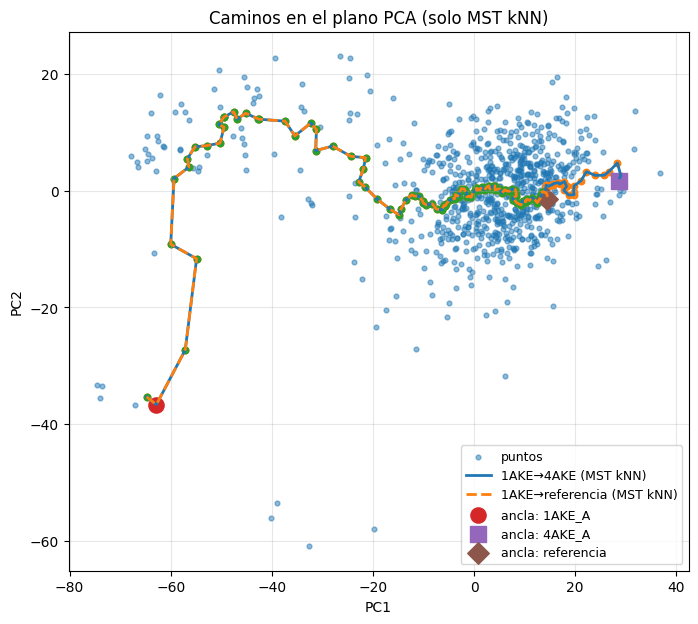

✅ Resultados en: /content/pca_paths_2_results
 - path_1AKE_to_4AKE: 137 nodos -> /content/pca_paths_2_results/path_1AKE_to_4AKE_path_names.csv
 - path_1AKE_to_ref: 114 nodos -> /content/pca_paths_2_results/path_1AKE_to_ref_path_names.csv
✅ Figura: /content/pca_paths_2_results/pca_paths_overlay.png


In [ ]:
# ============================================================
# 🧭 Caminos en PCA (solo /content, sin Drive) - SOLO MST(kNN)
# - Lee:
#   /content/pca_projection_kabsch_NO_RUIDO.csv  -> model, PC1, PC2
#   /content/pca_label_map_NO_RUIDO.csv          -> label_number, model
#
# Genera 2 caminos:
#   1) del punto más cercano a 1AKE_A al punto más cercano a 4AKE_A
#   2) del punto más cercano a 1AKE_A al punto más cercano a 'referencia'
# ============================================================
# Requisitos (una vez):
# !pip -q install networkx

import os, math, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
import networkx as nx

# ---------- RUTAS (NO Drive) ----------
PC_CSV  = "/content/pca_projection_kabsch_NO_RUIDO(2).csv"
MAP_CSV = "/content/pca_label_map_NO_RUIDO(2).csv"
OUT_DIR = "/content/pca_paths_2_results"
os.makedirs(OUT_DIR, exist_ok=True)

# ---------- CONFIG: puntos de referencia ----------
# Estos son los "anclajes" (cristalinos / puntos especiales)
ANCHOR_START_NAME = "1AKE_A"
ANCHOR_END1_NAME  = "4AKE_A"
ANCHOR_END2_NAME  = "referencia"  # debe existir en la columna 'model'

# Si quisieras usarlos por coordenadas en lugar de nombres, poné None arriba
# y definí aquí las coordenadas PCA (PC1, PC2):
ANCHOR_START_COORD = None  # ej. (62.8, -31.7)
ANCHOR_END1_COORD  = None
ANCHOR_END2_COORD  = None

# ---------- Parámetros de grafo ----------
K_NEIGHBORS = 18     # 15–25 suele ir bien
USE_MUTUAL  = False  # True = kNN mutuo (más robusto, menos aristas)

# ---------- CARGA ----------
df = pd.read_csv(PC_CSV)          # model, PC1, PC2
map_df = pd.read_csv(MAP_CSV)     # label_number, model

# unir para tener label_number junto con PC1/PC2
df = df.merge(map_df[['label_number','model']], on='model', how='left')

# matriz de puntos y nombres
X = df[['PC1','PC2']].to_numpy(float)
names = df['model'].astype(str).to_numpy()

# ---------- Helpers para índices/coordenadas ----------
def index_by_name(name):
    hits = np.where(names == str(name))[0]
    return int(hits[0]) if len(hits) else None

def coord_from_name(name):
    idx = index_by_name(name)
    if idx is None:
        raise ValueError(f"No se encontró el nombre '{name}' en la columna 'model'.")
    return X[idx]

def nearest_idx_to_anchor(anchor_name=None, anchor_coord=None, exclude_name=None):
    """
    Devuelve el índice del punto más cercano al ancla:
    - Si anchor_name está definido: toma su coordenada en PCA.
    - Si no, usa anchor_coord (tupla PC1,PC2).
    - Si exclude_name no es None, excluye todos los puntos con ese nombre
      (útil para que el "punto más cercano a 1AKE" NO sea 1AKE en sí).
    """
    if anchor_name is not None:
        base_xy = coord_from_name(anchor_name)
    elif anchor_coord is not None:
        base_xy = np.asarray(anchor_coord, float)
    else:
        raise ValueError("Definí anchor_name o anchor_coord.")

    base_xy = np.asarray(base_xy, float)
    mask = np.ones(len(X), dtype=bool)
    if exclude_name is not None:
        mask &= (names != str(exclude_name))

    if not np.any(mask):
        raise RuntimeError("La máscara de exclusión dejó 0 puntos.")

    X_masked = X[mask]
    d2 = np.sum((X_masked - base_xy)**2, axis=1)
    rel_idx = int(np.argmin(d2))
    global_indices = np.arange(len(X))[mask]
    return int(global_indices[rel_idx])

# ---------- Grafo k-NN ----------
def build_knn_edges(X, k=15, mutual=False):
    n = len(X)
    k = min(k+1, n)  # incluye self en la col 0
    nn = NearestNeighbors(n_neighbors=k).fit(X)
    dists, idxs = nn.kneighbors(X)
    edges = []
    for i in range(n):
        for d, j in zip(dists[i,1:], idxs[i,1:]):  # omitir self
            if mutual and i not in idxs[j,1:]:
                continue
            edges.append((int(i), int(j), float(d)))
    return np.array(edges, dtype=float), idxs, dists

edges, idxs, dists = build_knn_edges(X, K_NEIGHBORS, USE_MUTUAL)

# ---------- Método MST(kNN) ----------
def path_mst_knn(X, edges, s, t):
    G = nx.Graph()
    for i, j, d in edges:
        G.add_edge(int(i), int(j), weight=float(d))
    T = nx.minimum_spanning_tree(G, weight="weight")
    if not nx.has_path(T, s, t):
        raise RuntimeError("Sin camino en el MST (subí K_NEIGHBORS).")
    return nx.shortest_path(T, s, t, weight="weight")

# ---------- Resolver índices de los puntos "más cercanos" ----------
# Punto más cercano a 1AKE_A (excluyendo el propio 1AKE_A)
start_idx = nearest_idx_to_anchor(
    anchor_name=ANCHOR_START_NAME,
    anchor_coord=ANCHOR_START_COORD,
    exclude_name=ANCHOR_START_NAME
)

# Punto más cercano a 4AKE_A (excluyendo el propio 4AKE_A)
end1_idx = nearest_idx_to_anchor(
    anchor_name=ANCHOR_END1_NAME,
    anchor_coord=ANCHOR_END1_COORD,
    exclude_name=ANCHOR_END1_NAME
)

# Punto más cercano a 'referencia' (excluyendo el propio 'referencia')
end2_idx = nearest_idx_to_anchor(
    anchor_name=ANCHOR_END2_NAME,
    anchor_coord=ANCHOR_END2_COORD,
    exclude_name=ANCHOR_END2_NAME
)

print("Puntos seleccionados para los caminos:")
print(f" - cercano a {ANCHOR_START_NAME}: idx={start_idx}, name={names[start_idx]}")
print(f" - cercano a {ANCHOR_END1_NAME}:  idx={end1_idx},  name={names[end1_idx]}")
print(f" - cercano a {ANCHOR_END2_NAME}:  idx={end2_idx},  name={names[end2_idx]}")

# ---------- Calcular SOLO 2 caminos (MST) ----------
path_1AKE_to_4AKE = path_mst_knn(X, edges, start_idx, end1_idx)
path_1AKE_to_ref  = path_mst_knn(X, edges, start_idx, end2_idx)

def names_from_path(path_idx):
    return [names[i] for i in path_idx]

paths = {
    "path_1AKE_to_4AKE": path_1AKE_to_4AKE,
    "path_1AKE_to_ref":  path_1AKE_to_ref,
}
path_names = {k: names_from_path(v) for k, v in paths.items()}

# ---------- Guardar listas ----------
for tag, lst in path_names.items():
    pd.DataFrame({"order": range(len(lst)), "name": lst}).to_csv(
        f"{OUT_DIR}/{tag}_path_names.csv", index=False
    )

# ---------- Plot ----------
plt.figure(figsize=(8,7))
plt.scatter(X[:,0], X[:,1], s=12, alpha=0.5, label="puntos")

def draw_path(path, style, label):
    XY = X[np.array(path)]
    plt.plot(XY[:,0], XY[:,1], style, linewidth=2.0, label=label)
    plt.scatter(XY[:,0], XY[:,1], s=22)

draw_path(path_1AKE_to_4AKE, '-',  "1AKE→4AKE (MST kNN)")
draw_path(path_1AKE_to_ref,  '--', "1AKE→referencia (MST kNN)")

# marcamos los tres anclajes originales (cristales / puntos especiales)
for name, marker, color in [
    (ANCHOR_START_NAME, 'o', 'black'),
    (ANCHOR_END1_NAME,  's', 'black'),
    (ANCHOR_END2_NAME,  'D', 'black')
]:
    idx = index_by_name(name)
    if idx is not None:
        plt.scatter([X[idx,0]], [X[idx,1]], s=120, marker=marker, label=f"ancla: {name}")

plt.title("Caminos en el plano PCA (solo MST kNN)")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.legend(loc="best", fontsize=9)
plt.grid(True, alpha=0.3)
fig_path = f"{OUT_DIR}/pca_paths_overlay.png"
plt.savefig(fig_path, dpi=200, bbox_inches="tight")
plt.show()

print("✅ Resultados en:", OUT_DIR)
for k, v in paths.items():
    print(f" - {k}: {len(v)} nodos -> {OUT_DIR}/{k}_path_names.csv")
print("✅ Figura:", fig_path)


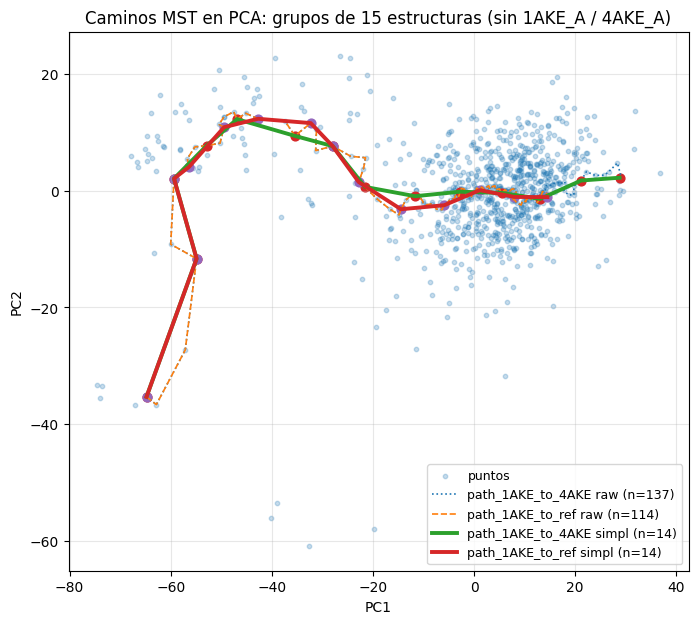

✅ Resultados en: /content/pca_paths_2_results
 - path_1AKE_to_4AKE: sin cristales n= 136, len= 181.24 | simpl n=  14, len= 136.30 -> /content/pca_paths_2_results/path_1AKE_to_4AKE_path_names_simplified.csv
 - path_1AKE_to_ref: sin cristales n= 113, len= 158.27 | simpl n=  14, len= 123.67 -> /content/pca_paths_2_results/path_1AKE_to_ref_path_names_simplified.csv
✅ Figura: /content/pca_paths_2_results/pca_paths_simplified_groups.png
(Simplificación) MAX_POINTS=15, excluyendo {'4AKE_A', '1AKE_A'}

Ejemplo nombres seleccionados (primer camino):
path_1AKE_to_4AKE: ['query_msa_degree_frac0.80_str0.80_seed11__ACT-promote_joint__MODE-degree__A-0_05__G-3__MINSEP-12__DF-0_model_0', 'query_msa_degree_frac0.60_str0.80_seed33__ACT-promote__MODE-degree__A-0_1__G-3__MINSEP-8__DF-0_model_0', 'query_msa_degree_frac0.20_str0.40_seed11__ACT-promote_joint__MODE-degree__A-0_05__G-3__MINSEP-12__DF-0_model_0', 'query_msa_degree_frac0.60_str0.80_seed11__ACT-promote_joint__MODE-degree__A-0_05__G-3__MINSEP-12__

In [ ]:
# ============================================================
# 🧭 Post-proceso de caminos MST: 15 estructuras sin cristales
# Usa como INPUT los outputs del bloque anterior:
#   /content/pca_paths_2_results/path_1AKE_to_4AKE_path_names.csv
#   /content/pca_paths_2_results/path_1AKE_to_ref_path_names.csv
#
# Además necesita la proyección PCA para obtener coordenadas:
#   /content/pca_projection_kabsch_NO_RUIDO(2).csv  (model, PC1, PC2)
#
# Condiciones:
#   - 15 estructuras representativas por camino (≈ MAX_POINTS)
#   - Excluir 1AKE_A y 4AKE_A de los grupos finales
#   - Conservar las dos puntas del camino (inicio y fin, ya sin cristales)
#   - Mostrar gráficamente qué estructuras quedaron en cada grupo
# ============================================================

import os, numpy as np, pandas as pd, matplotlib.pyplot as plt

# ---------- Rutas (deben coincidir con el bloque anterior) ----------
PC_CSV   = "/content/pca_projection_kabsch_NO_RUIDO(2).csv"
OUT_DIR  = "/content/pca_paths_2_results"
os.makedirs(OUT_DIR, exist_ok=True)

# ---------- Parámetros ----------
MAX_POINTS     = 15
BANNED_NAMES   = {"1AKE_A", "4AKE_A"}   # cristales a excluir de los 15 finales

# ---------- Carga de datos ----------
df = pd.read_csv(PC_CSV)  # columnas: model, PC1, PC2
# Mapa nombre->(PC1,PC2)
coord = df.set_index("model")[["PC1","PC2"]].to_dict("index")

def load_path_names(tag):
    """Lee un camino crudo generado antes, devuelve lista de nombres."""
    path_csv = f"{OUT_DIR}/{tag}_path_names.csv"
    if not os.path.exists(path_csv):
        raise FileNotFoundError(f"No encuentro {path_csv}. ¿Corriste el bloque anterior?")
    return pd.read_csv(path_csv)["name"].astype(str).tolist()

def names_to_xy(names):
    """Convierte lista de modelos a array Nx2 de coordenadas (PC1,PC2)."""
    pts = []
    missing = []
    for n in names:
        if n in coord:
            pts.append([coord[n]["PC1"], coord[n]["PC2"]])
        else:
            missing.append(n)
    if missing:
        print(f"⚠️ Aviso: {len(missing)} nombres no tienen coordenadas y se omiten (ej: {missing[:3]} ...)")
    return np.array(pts, float)

def simplify_uniform_keep_endpoints(names, max_points):
    """
    Selección aproximadamente uniforme a lo largo del camino,
    CONSERVANDO SIEMPRE:
      - el primer elemento (punto inicial)
      - el último elemento (punto final)
    """
    if (max_points is None) or (len(names) <= max_points):
        return names

    XY = names_to_xy(names)
    if len(XY) <= 2:
        return names

    # longitud acumulada a lo largo del camino en el espacio PC1/PC2
    seg = np.sqrt(np.sum(np.diff(XY, axis=0)**2, axis=1))
    cum = np.concatenate([[0.0], np.cumsum(seg)])
    total = cum[-1]
    targets = np.linspace(0, total, max_points)

    out = []
    for t in targets:
        i = np.searchsorted(cum, t, side="left")
        i = min(i, len(names)-1)
        out.append(names[i])

    # asegurar extremos y quitar consecutivos duplicados
    out[0]  = names[0]
    out[-1] = names[-1]
    uniq = [out[0]]
    for v in out[1:]:
        if v != uniq[-1]:
            uniq.append(v)
    return uniq

def path_length(names):
    XY = names_to_xy(names)
    if len(XY) < 2:
        return 0.0
    return float(np.sum(np.sqrt(np.sum(np.diff(XY,axis=0)**2,axis=1))))

# ---------- Procesa SOLO LOS 2 CAMINOS ----------
tags = ["path_1AKE_to_4AKE", "path_1AKE_to_ref"]

paths_raw = {}
paths_no_crystals = {}
paths_simpl = {}

for t in tags:
    raw = load_path_names(t)
    paths_raw[t] = raw

    # 1) quitamos cristales (pero mantenemos orden)
    no_crystals = [n for n in raw if n not in BANNED_NAMES]
    if len(no_crystals) < 2:
        raise RuntimeError(f"El camino {t} se quedó sin puntos suficientes tras quitar cristales.")
    paths_no_crystals[t] = no_crystals

    # 2) simplificación uniforme sobre el camino SIN cristales
    simpl = simplify_uniform_keep_endpoints(no_crystals, MAX_POINTS)
    paths_simpl[t] = simpl

    # chequeo: puntas del camino sin cristales deben estar en el grupo simplificado
    if no_crystals[0] not in simpl or no_crystals[-1] not in simpl:
        raise RuntimeError(f"La simplificación del camino {t} perdió una de las puntas (sin cristales).")

    # chequeo: que los cristales no estén en el grupo final
    bad = [n for n in simpl if n in BANNED_NAMES]
    if bad:
        raise RuntimeError(f"El camino simplificado {t} aún contiene cristales: {bad}")

# ---------- Guarda CSV de caminos simplificados ----------
for t in tags:
    out_csv = f"{OUT_DIR}/{t}_path_names_simplified.csv"
    pd.DataFrame({
        "order": range(len(paths_simpl[t])),
        "name":  paths_simpl[t]
    }).to_csv(out_csv, index=False)

# ---------- Plot: muestra qué estructuras quedaron en cada grupo ----------
plt.figure(figsize=(8,7))
plt.scatter(df["PC1"], df["PC2"], s=10, alpha=0.25, label="puntos")

def draw_by_names(names, style, label, lw=2.0, scatter_size=25):
    XY = names_to_xy(names)
    if len(XY) >= 2:
        plt.plot(XY[:,0], XY[:,1], style, linewidth=lw, label=label)
    plt.scatter(XY[:,0], XY[:,1], s=scatter_size)

# colores/estilos para distinguir caminos y simplificados
# (no importa el color concreto, solo que sean distintos)
styles_raw = {
    "path_1AKE_to_4AKE": ":",
    "path_1AKE_to_ref":  "--",
}
styles_simpl = {
    "path_1AKE_to_4AKE": "-",
    "path_1AKE_to_ref":  "-",
}

# Caminos crudos (sin quitar cristales) – líneas finas
for t in tags:
    draw_by_names(paths_raw[t],
                  styles_raw[t],
                  f"{t} raw (n={len(paths_raw[t])})",
                  lw=1.2, scatter_size=0)  # no marcamos puntos crudos

# Caminos simplificados (ya sin cristales) – líneas gruesas + puntos grandes
for t in tags:
    draw_by_names(paths_simpl[t],
                  styles_simpl[t],
                  f"{t} simpl (n={len(paths_simpl[t])})",
                  lw=2.8, scatter_size=40)

plt.title("Caminos MST en PCA: grupos de 15 estructuras (sin 1AKE_A / 4AKE_A)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(loc="best", fontsize=9)
plt.grid(True, alpha=0.3)

fig_path = f"{OUT_DIR}/pca_paths_simplified_groups.png"
plt.savefig(fig_path, dpi=220, bbox_inches="tight")
plt.show()

# ---------- Resumen ----------
print("✅ Resultados en:", OUT_DIR)
for t in tags:
    Lr = path_length(paths_no_crystals[t])
    Ls = path_length(paths_simpl[t])
    print(f" - {t:16s}: sin cristales n={len(paths_no_crystals[t]):4d}, len={Lr:7.2f} | "
          f"simpl n={len(paths_simpl[t]):4d}, len={Ls:7.2f} -> "
          f"{OUT_DIR}/{t}_path_names_simplified.csv")

print("✅ Figura:", fig_path)
print(f"(Simplificación) MAX_POINTS={MAX_POINTS}, excluyendo {BANNED_NAMES}")
print("\nEjemplo nombres seleccionados (primer camino):")
print("path_1AKE_to_4AKE:", paths_simpl["path_1AKE_to_4AKE"])
